# Formula 1 Tire Degradation Classification


## Imports &  Installations

In [ ]:
# Installations
%pip install fastf1 numba imbalanced-learn xgboost sktime scikit-learn
%pip install torch --index-url https://download.pytorch.org/whl/cpu

In [ ]:
# Imports
import numpy as np
import fastf1
import os
import pandas as pd
import time
import pickle
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, make_scorer, f1_score
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import RandomizedSearchCV
from torch.utils.data import WeightedRandomSampler




In [2]:
# Fast F1 Cache
cache_dir = './cache'
if not os.path.exists(cache_dir):
    os.makedirs(cache_dir)

fastf1.Cache.enable_cache(cache_dir)

## Data Import & Processing

In [3]:
# Dirty Air Effect Distance In Meters (from research, cited in Progress Report)
# Citation: noble2025dirtyair in the Progress Report
DIRTY_AIR_THRESH_METERS = 20

# Fuel Flow Constants
fuelDensityKgPerLitre = 0.727 # Citation: autosport2025fuelconsumption in the Progress Report
fiaMinFuelLoadLitre = 1 # Citation: fia2023techregs in the Progress Report
fiaMinFuelLoadKg = fuelDensityKgPerLitre * fiaMinFuelLoadLitre

### Helper Functions

In [1]:
# Fuel Consumption helper functions

# Calculates the fuel consumed (kg) during a specific deltaT
# based on the Throttle and RPM
# from the FIA regulatory fuel flow formula.
def instantaneousFuelUsage(throttle, rpm, deltaT):
    # Calculate the maximum allowed fuel flow rate at this RPM (from FIA regulations)
    # Formula's Citation: fia2023techregs in the Progress Report
    maxFlowRateKgH = np.minimum(100.0, 0.009 * rpm + 5.5)

    # Scale the flow rate by throttle input percentage
    realFlowRateKgH = (throttle / 100.0) * maxFlowRateKgH

    # Convert the flow rate from kg/hour to kg/second
    realFlowRateKgS = realFlowRateKgH / 3600.0

    # Multiply by the time delta to
    # find the total fuel kg consumed in this slice
    fuelBurnedKg = realFlowRateKgS * deltaT

    return fuelBurnedKg

# Calculate the entire FuelLoad column from Throttle, RPM, DeltaT
def calculateFuelLoadDfColumn(throttle, rpm, deltaT):
  # Get the burn slices for every timestamp across the whole race
  burnSlices = instantaneousFuelUsage(throttle, rpm, deltaT)

  # Reverse the array so we start at the final lap of the stint
  reversedSlices = burnSlices[::-1]

  # Integrate the slices together backward starting from the known min fuel
  reversedFuelCol = np.cumsum(reversedSlices) + fiaMinFuelLoadKg

  # Return original chronological order
  fuelLoadCol = reversedFuelCol[::-1]
  return fuelLoadCol

In [5]:
# Storing all samples, each entry is one addSample call, a row of all the data points
allSamples = []

def addSample(year, race, driver, lapNumber, corner, 
              tireCompound, tireAge, fuelLoad, 
               speedPoints, throttlePoints, brakePoints, gearPoints):
    # Append one corner sample to allSamples
    allSamples.append({
        'Year': year,
        'Race': race,
        'Driver': driver,
        'LapNumber': lapNumber,
        'Corner': corner,
        'TireCompound': tireCompound,
        'TireAge': tireAge,
        'FuelLoad': fuelLoad,
        'Speed': speedPoints,  # 100 data points 
        'Throttle': throttlePoints, # 100 data points 
        'Brake': brakePoints, # 100 data points 
        'Gear': gearPoints, # 100 data points 
    })

In [6]:
# Corner Boundary Identification Helper Funcs
# Constants - decided by me
MAX_WINDOW_SIDE_SIZE = 250 # in meters
MAX_FALLBACK_WINDOW_SIDE_SIZE = 80 # in meters
SUSTAINED_SECS = 0.3 # secs a signals holds to be continous

# Citation: fastf1carapi in the Progress Report
DRSActiveCodes = [10, 12, 14]

# Returns window around corner based on midpoint 
# of the distance to the prev and next corners
def cornerWindow(cornerPos, prevCornerPos, nextCornerPos):
    prevHalf = min(MAX_WINDOW_SIDE_SIZE, (cornerPos - prevCornerPos)/2)
    nextHalf = min(MAX_WINDOW_SIDE_SIZE, (nextCornerPos - cornerPos)/2)
    return (cornerPos - prevHalf), (cornerPos + nextHalf)

# Fallback corner is smaller (for when there is no signficant tel data)
def fallbackWindow(cornerPos, prevCornerPos, nextCornerPos):
    prevHalf = min(MAX_FALLBACK_WINDOW_SIDE_SIZE, (cornerPos - prevCornerPos)/4)
    nextHalf = min(MAX_FALLBACK_WINDOW_SIDE_SIZE, (nextCornerPos - cornerPos)/4)
    return (cornerPos - prevHalf), (cornerPos + nextHalf)

# Uses telemetry and corner window to accurately determine 
# the exact region relevant data
def cornerBoundaries(tel, cornerPos, prevCornerPos, nextCornerPos, deltaTColumn):
    # Form window for this corner
    windowStart, windowEnd = cornerWindow(cornerPos, prevCornerPos, nextCornerPos)
    window = tel[(tel['Distance'] >= windowStart) & (tel['Distance'] <= windowEnd)].copy()

    # Edge case
    fallBackStart, fallBackEnd = fallbackWindow(cornerPos, prevCornerPos, nextCornerPos)
    if (window.empty):
        return fallBackStart, fallBackEnd
    
    # Find sample rate (avg deltaT)
    avgDeltaT = deltaTColumn.mean()

    # Convert sample rate to samples per sustained duration
    # With Safety - ensure avgDeltaT doesnt force a crash
    if (avgDeltaT and avgDeltaT > 0):
        sustainedSamples = max(1, round(SUSTAINED_SECS/avgDeltaT))
    else:
        sustainedSamples = 1

    # Corner Entry Detection (Brake on = true OR gear decrease)
    brakeOnCol = window['Brake'] == True
    downshiftCol = window['nGear'].diff() < 0

    entryCandidates = window[brakeOnCol | downshiftCol]
    # Position of first possible entry canditate
    entryPos = entryCandidates['Distance'].iloc[0] if not entryCandidates.empty else None

    # Corner Exit Detection (rise in Throttle and Gear)
    # Update search zone to be after entry
    exitSearchZone = window if entryPos is None else window[window['Distance'] > entryPos]
    
    # Isolate relevant tel behaviour
    throttleIncrCol = exitSearchZone['Throttle'].diff() > 0
    upshiftCol = exitSearchZone['nGear'].diff() > 0
    exitBothIncr = throttleIncrCol & upshiftCol

    # Find first point where speed up behaviour is sustained for sustained samples
    sustainedSpeedUp = exitBothIncr.rolling(sustainedSamples).sum() == sustainedSamples
    exitCandidates = exitSearchZone[sustainedSpeedUp]
    exitPos = exitCandidates['Distance'].iloc[0] if not exitCandidates.empty else None

    # Edge case (in case of fall back i.e. no tel corner)
    if ((entryPos is None) and (exitPos is None)):
        return fallBackStart, fallBackEnd

    finalEntry = entryPos if entryPos is not None else fallBackStart
    finalExit = exitPos if exitPos is not None else fallBackEnd
    
    return finalEntry, finalExit

In [ ]:
# Load the races in a given year, return as (Year, Race)
def getRaceList(years):
    raceList = []
    for year in years:
        schedule = fastf1.get_event_schedule(year, include_testing=False)
        for _, event in schedule.iterrows():
            raceList.append([year, event['EventName']])
    return raceList

In [ ]:
# Data Processing Pipeline 2023
raceLevelSummary = []
allSamples = []

loadRaces23 = getRaceList([2023])

# Save all data to disk
os.makedirs('output', exist_ok = True)
for year, race in loadRaces23:
    # Safe loading so crash doesnt disrupt the run
    try:
        session = fastf1.get_session(year, race, 'R')
        session.load()
    except Exception as e:
        print(f"  SKIPPING {year} {race}: failed to load ({e})", flush = True)
        continue

    # Race loop start time and print race details
    raceStartTime = time.time()
    print(f"\n=== {year} {race} ===", flush =True)

    # Extract track specfic information
    circuitInfo = session.get_circuit_info()
    corners = circuitInfo.corners.sort_values('Distance').reset_index(drop = True)
    print(f"  Corners found: {len(corners)}", flush =True)

    # Race data counters - for verifying success
    samplesBeforeRace = len(allSamples)
    raceCornersAttempted = 0
    raceSkippedEmpty = 0
    raceSkippedDRS = 0
    raceSkippedDirtyAir = 0

    # Go through each driver
    for driver in session.drivers:
        driverStartTime = time.time()
        currDriverLaps = session.laps.pick_drivers(driver)

        # Process all laps 
        tempAllLapsList = []
        for i, lap in currDriverLaps.iterlaps():
            curLapTel = lap.get_telemetry().add_distance()

            # Add lap number to tel
            curLapTel['LapNumber'] = lap['LapNumber']

            # Add to temp list
            tempAllLapsList.append(curLapTel)

        # Ensure list is not empty
        if not tempAllLapsList:
            print(f"  Driver {driver} has no laps, skipping", flush=True)
            continue

        # Combine seperate lap data along tel data
        # For safety, reshuffle along time axis + create new index
        fullRaceTel = pd.concat(tempAllLapsList).sort_values('SessionTime').reset_index(drop = True)

        # Fuel Load Calculation
        # Calc the float time difference between each tel sample (account for col 0 giving NaN)
        deltaTCol = fullRaceTel['SessionTime'].diff().dt.total_seconds().fillna(0)  

        # Use helper function to fill FuelLoad calc
        fullRaceTel['FuelLoad'] = calculateFuelLoadDfColumn(throttle = fullRaceTel['Throttle'], rpm = fullRaceTel['RPM'], deltaT = deltaTCol)

        # Exclude invalid laps (racing laps at full pace)
        validLaps = currDriverLaps.pick_quicklaps() # Filter fast laps
        validLaps = validLaps.pick_wo_box() # Remove inlaps/outlaps
        validLaps = validLaps.pick_track_status('1', how = 'equals') # Keep only laps that are entirely green flag(full speed) laps
        validLaps = validLaps.pick_compounds(['SOFT', 'MEDIUM', 'HARD']) # Exclude wet/inter tires (not in our output scope)

        # For safety, explcitly remove the formation lap
        validLaps = validLaps[validLaps['LapNumber'] >= 1]

        if validLaps.empty: 
            print(f"  Driver {driver} has no valid laps, skipping", flush=True)
            continue

        # Process the valid laps for next steps (add lap Number, stitch laps)
        driverAheadLaps = []
        # Isolate the lap numbers of valid laps
        validLapNums = set(validLaps['LapNumber'])
        for lapTel in tempAllLapsList:
            # Isolate the lap number and check its valid
            if lapTel['LapNumber'].iloc[0] in validLapNums:
                # Copy tel, add driver ahead data, and append to new list
                driverAheadLapTel = lapTel.copy().add_driver_ahead()
                driverAheadLaps.append(driverAheadLapTel)
        driverAheadTel = pd.concat(driverAheadLaps).reset_index(drop=True) if driverAheadLaps else pd.DataFrame()

        # Per driver data counters
        cornersAttempted = 0
        skippedEmpty = 0
        skippedDRS = 0
        skippedDirtyAir = 0

        # Loop through valid laps
        for i, lap in validLaps.iterlaps():
            # Isolate now for final data output
            lapNum = lap['LapNumber']
            tireComp = lap['Compound']
            tireAge = lap['TyreLife']

            # Isolate telemetery for this lap only
            lapTel = fullRaceTel[fullRaceTel['LapNumber'] == lapNum]
            lapDrivAheadTel = driverAheadTel[driverAheadTel['LapNumber'] == lapNum] if not driverAheadTel.empty else None

            # For safety
            if (lapTel.empty or lapDrivAheadTel is None or lapDrivAheadTel.empty):
                continue

            # Loop over corners; acquire corner, prev, and next
            # Handle first/last corner to naturally trigger the max window size
            for cornerIndex in range(len(corners)):
                cornersAttempted += 1
                currCornerPos = corners.loc[cornerIndex, 'Distance'] 
                prevCornerPos = corners.loc[cornerIndex - 1, 'Distance'] if cornerIndex > 0 else float('-inf')
                nextCornerPos = corners.loc[cornerIndex + 1, 'Distance'] if cornerIndex < len(corners) - 1 else float('inf')

                # Detect the boundary
                entryPos, exitPos = cornerBoundaries(lapTel, currCornerPos, prevCornerPos, nextCornerPos, deltaTCol)
                cornerTel = lapTel[(lapTel['Distance'] >= entryPos) & (lapTel['Distance'] <= exitPos)]

                # np.interp later requires at least 2 points
                if cornerTel.empty or len(cornerTel) < 2:
                    skippedEmpty += 1
                    continue

                # Check for and remove Dirty Air/ DRS active corner approaches
                # Check if DRS is active in anyway at any point in the corner
                drsActive = cornerTel['DRS'].isin(DRSActiveCodes).any()
                dirtyAir = False

                # Isolate telem for this corner with driver ahead column
                if (lapDrivAheadTel is not None):
                    cornerDrivAhead = lapDrivAheadTel[(lapDrivAheadTel['Distance'] >= entryPos) & (lapDrivAheadTel['Distance'] <= exitPos)]
                    # Check if driver is ever within dirty air effect range
                    if (not cornerDrivAhead.empty):
                        dirtyAir = (cornerDrivAhead['DistanceToDriverAhead'] < DIRTY_AIR_THRESH_METERS).any()

                if drsActive:
                    skippedDRS += 1
                    continue
                if dirtyAir:
                    skippedDirtyAir += 1
                    continue

                # Normalize corner data to 100 points
                normalPoints = 100
                oldPointDiff = np.linspace(0, 1, len(cornerTel))
                nexPointDiff = np.linspace(0, 1, normalPoints)

                speedPoints = np.interp(nexPointDiff, oldPointDiff, cornerTel['Speed'].values)
                throttlePoints = np.interp(nexPointDiff, oldPointDiff, cornerTel['Throttle'].values)
                brakePoints = np.interp(nexPointDiff, oldPointDiff, cornerTel['Brake'].astype(float).values)
                gearPoints = np.interp(nexPointDiff, oldPointDiff, cornerTel['nGear'].values)

                # Acquire fuel at corner
                cornerFuel = cornerTel['FuelLoad'].mean()

                # Create and append finished sample
                addSample(year = year, race = race, driver = driver, 
                                            lapNumber = lapNum,corner=cornerIndex + 1, tireCompound=tireComp.capitalize(), 
                                            tireAge = tireAge, fuelLoad = cornerFuel, speedPoints=speedPoints, 
                                            throttlePoints=throttlePoints, brakePoints= brakePoints, gearPoints= gearPoints)
                
        # Update race level stats
        raceCornersAttempted += cornersAttempted
        raceSkippedEmpty += skippedEmpty
        raceSkippedDRS += skippedDRS
        raceSkippedDirtyAir += skippedDirtyAir

        # Summarize driver stats
        print(f"  Driver {driver}: {cornersAttempted} attempted, "
            f"{cornersAttempted - skippedEmpty - skippedDRS - skippedDirtyAir} samples "
            f"({time.time() - driverStartTime:.1f}s)", flush=True)
    
    # Race level stats
    raceSamples = len(allSamples) - samplesBeforeRace
    raceLevelSummary.append({
        'Year': year, 'Race': race,
        'Attempted': raceCornersAttempted, 'Empty': raceSkippedEmpty,
        'DRS': raceSkippedDRS, 'DirtyAir': raceSkippedDirtyAir,
        'Samples': raceSamples,
    })
    print(f"  === {race} done: {raceSamples} samples in {time.time() - raceStartTime:.1f}s "
          f"(running total: {len(allSamples)}) ===", flush=True)  

    # Checkpoint every race so a later crash doesnt lose progress
    pd.DataFrame(allSamples).to_pickle('output/2023_samples_checkpoint.pkl')          

# Full dataset summaries
print("\n\n--- Full dataset summary ---")
summaryDf = pd.DataFrame(raceLevelSummary)
print(summaryDf.to_string(index=False))
print(f"\nTotal samples across all races: {len(allSamples)}")

allSamplesDF = pd.DataFrame(allSamples)
print(f"\nFinal DataFrame shape: {allSamplesDF.shape}")
print(allSamplesDF['TireCompound'].value_counts())   

# Save full dataset, pickle preservers 100p telm columms
with open('output/2023_samples.pkl', 'wb') as file:
    pickle.dump(allSamplesDF, file)

# Save summary as csv
summaryDf.to_csv('output/race_summary_2023.csv', index=False)

print("Saved 2023_samples.pkl and race_summary_2023.csv to /output")

core           INFO 	Loading data for Bahrain Grand Prix - Race [v3.8.3]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for lap_count
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...
req            INFO 	Using cached data for car_data
req            INFO 	Using cached data for position_data
req            INFO 	Using cached data for weather_data
req            INFO 	Using cached data for race_control_messages
core           INFO 	Finished loading data for 20 drivers: ['1', '11', '14', '55', '44', '18', '63', '77', '10', '23', '22', '2', '20', '21', '27', '24', '4', '31', '16', '81']



=== 2023 Bahrain Grand Prix ===
  Corners found: 15
  Driver 1: 735 attempted, 674 samples (26.0s)
  Driver 11: 735 attempted, 619 samples (23.7s)
  Driver 14: 735 attempted, 615 samples (23.9s)
  Driver 55: 735 attempted, 668 samples (23.7s)
  Driver 44: 735 attempted, 631 samples (23.6s)
  Driver 18: 735 attempted, 642 samples (24.0s)
  Driver 63: 735 attempted, 620 samples (23.5s)
  Driver 77: 735 attempted, 645 samples (23.6s)
  Driver 10: 735 attempted, 544 samples (23.6s)
  Driver 23: 735 attempted, 617 samples (23.4s)
  Driver 22: 735 attempted, 473 samples (23.8s)
  Driver 2: 720 attempted, 583 samples (23.7s)
  Driver 20: 720 attempted, 629 samples (23.3s)
  Driver 21: 720 attempted, 608 samples (23.2s)
  Driver 27: 720 attempted, 594 samples (23.6s)
  Driver 24: 555 attempted, 443 samples (21.1s)
  Driver 4: 570 attempted, 489 samples (20.7s)
  Driver 31: 450 attempted, 402 samples (16.0s)
  Driver 16: 495 attempted, 452 samples (16.8s)
  Driver 81: 150 attempted, 96 samples

core           INFO 	Loading data for Saudi Arabian Grand Prix - Race [v3.8.3]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for lap_count
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...
core        WARNING 	Driver 11 completed the race distance 00:00.035000 before the recorded end of the session.
req            INFO 	Using cached data for car_data
req            INFO 	Using cached data for position_data
req            INFO 	Using cached data for weather_data
req            INFO 	Using cached data for race_control_messages
core           INFO 	Finished loading data for 20 drivers: ['11', '1', '14', '63', '44', '55', '16', '31', '10', '20', '


=== 2023 Saudi Arabian Grand Prix ===
  Corners found: 27
  Driver 11: 1242 attempted, 1142 samples (23.2s)
  Driver 1: 1215 attempted, 1101 samples (21.9s)
  Driver 14: 1242 attempted, 1118 samples (22.5s)
  Driver 63: 1242 attempted, 1174 samples (22.1s)
  Driver 44: 1215 attempted, 1136 samples (22.4s)
  Driver 55: 1161 attempted, 1036 samples (21.5s)
  Driver 16: 1188 attempted, 1095 samples (21.7s)
  Driver 31: 1188 attempted, 1076 samples (21.7s)
  Driver 10: 1161 attempted, 1049 samples (21.6s)
  Driver 20: 1161 attempted, 953 samples (21.8s)
  Driver 22: 1215 attempted, 1135 samples (22.1s)
  Driver 27: 1161 attempted, 1019 samples (21.6s)
  Driver 24: 1161 attempted, 933 samples (30.8s)
  Driver 21: 1188 attempted, 943 samples (23.5s)
  Driver 81: 1188 attempted, 1009 samples (24.1s)
  Driver 2: 1215 attempted, 1047 samples (23.1s)
  Driver 4: 1161 attempted, 926 samples (22.8s)
  Driver 77: 1080 attempted, 963 samples (22.2s)
  Driver 23: 567 attempted, 434 samples (12.1s)
 

core           INFO 	Loading data for Australian Grand Prix - Race [v3.8.3]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for lap_count
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...
req            INFO 	Using cached data for car_data
req            INFO 	Using cached data for position_data
req            INFO 	Using cached data for weather_data
req            INFO 	Using cached data for race_control_messages
core           INFO 	Finished loading data for 20 drivers: ['1', '44', '14', '18', '11', '4', '27', '81', '24', '22', '77', '55', '10', '31', '21', '2', '20', '63', '23', '16']



=== 2023 Australian Grand Prix ===
  Corners found: 14
  Driver 1: 602 attempted, 578 samples (24.9s)
  Driver 44: 602 attempted, 584 samples (24.4s)
  Driver 14: 602 attempted, 580 samples (25.5s)
  Driver 18: 602 attempted, 525 samples (27.2s)
  Driver 11: 588 attempted, 519 samples (24.7s)
  Driver 4: 602 attempted, 549 samples (26.3s)
  Driver 27: 602 attempted, 521 samples (25.4s)
  Driver 81: 602 attempted, 536 samples (25.4s)
  Driver 24: 602 attempted, 493 samples (26.0s)
  Driver 22: 602 attempted, 577 samples (25.3s)
  Driver 77: 602 attempted, 497 samples (26.6s)
  Driver 55: 602 attempted, 516 samples (25.0s)
  Driver 10: 602 attempted, 528 samples (25.4s)
  Driver 31: 602 attempted, 515 samples (25.0s)
  Driver 21: 560 attempted, 505 samples (24.2s)
  Driver 2: 560 attempted, 521 samples (25.4s)
  Driver 20: 602 attempted, 509 samples (25.3s)
  Driver 63: 126 attempted, 94 samples (7.5s)
  Driver 23: 42 attempted, 31 samples (2.8s)
  Driver 16 has no valid laps, skipping


... (34 outputs left out)

core           INFO 	Loading data for Las Vegas Grand Prix - Race [v3.8.3]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for lap_count
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...
core        WARNING 	Driver 1 completed the race distance 00:00.001000 before the recorded end of the session.
req            INFO 	Using cached data for car_data
req            INFO 	Using cached data for position_data
req            INFO 	Using cached data for weather_data
req            INFO 	Using cached data for race_control_messages
core           INFO 	Finished loading data for 20 drivers: ['1', '16', '11', '31', '18', '55', '44', '63', '14', '81', '10', 


=== 2023 Las Vegas Grand Prix ===
  Corners found: 17
  Driver 1: 578 attempted, 438 samples (22.1s)
  Driver 16: 578 attempted, 442 samples (23.0s)
  Driver 11: 595 attempted, 373 samples (22.8s)
  Driver 31: 595 attempted, 440 samples (22.9s)
  Driver 18: 595 attempted, 420 samples (22.9s)
  Driver 55: 595 attempted, 397 samples (22.6s)
  Driver 44: 561 attempted, 329 samples (22.3s)
  Driver 63: 578 attempted, 363 samples (22.6s)
  Driver 14: 595 attempted, 389 samples (22.4s)
  Driver 81: 510 attempted, 380 samples (21.4s)
  Driver 10: 561 attempted, 413 samples (23.1s)
  Driver 23: 578 attempted, 422 samples (22.8s)
  Driver 20: 595 attempted, 353 samples (23.1s)
  Driver 3: 544 attempted, 350 samples (21.7s)
  Driver 24: 612 attempted, 404 samples (23.3s)
  Driver 2: 578 attempted, 431 samples (22.7s)
  Driver 77: 544 attempted, 451 samples (21.9s)
  Driver 22: 493 attempted, 406 samples (20.3s)
  Driver 27: 527 attempted, 351 samples (20.9s)
  Driver 4 has no valid laps, skippi

core           INFO 	Loading data for Abu Dhabi Grand Prix - Race [v3.8.3]
req            INFO 	No cached data found for session_info. Loading data...
_api           INFO 	Fetching session info data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for driver_info. Loading data...
_api           INFO 	Fetching driver list...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for session_status_data. Loading data...
_api           INFO 	Fetching session status data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for lap_count. Loading data...
_api           INFO 	Fetching lap count data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for track_status_data. Loading data...
_api           INFO 	Fetching track status data...
req            INFO 	Data has been written to cache!
req            INFO 	No 


=== 2023 Abu Dhabi Grand Prix ===
  Corners found: 16
  Driver 1: 864 attempted, 789 samples (40.8s)
  Driver 16: 864 attempted, 795 samples (41.3s)
  Driver 63: 848 attempted, 684 samples (40.8s)
  Driver 11: 848 attempted, 688 samples (40.9s)
  Driver 4: 864 attempted, 756 samples (41.1s)
  Driver 81: 864 attempted, 708 samples (40.7s)
  Driver 14: 848 attempted, 650 samples (39.8s)
  Driver 22: 896 attempted, 764 samples (41.4s)
  Driver 44: 848 attempted, 649 samples (39.9s)
  Driver 18: 848 attempted, 703 samples (40.5s)
  Driver 3: 848 attempted, 693 samples (39.9s)
  Driver 31: 880 attempted, 754 samples (41.0s)
  Driver 10: 848 attempted, 744 samples (38.9s)
  Driver 23: 848 attempted, 765 samples (40.0s)
  Driver 27: 848 attempted, 717 samples (39.7s)
  Driver 2: 848 attempted, 725 samples (39.6s)
  Driver 24: 848 attempted, 723 samples (39.8s)
  Driver 55: 832 attempted, 747 samples (40.5s)
  Driver 77: 864 attempted, 736 samples (39.8s)
  Driver 20: 832 attempted, 754 sampl

In [ ]:
# Data Processing Pipeline 2024
raceLevelSummary = []
allSamples = []

loadRaces24 = getRaceList([2024])
print(f"Loaded {len(loadRaces24)} races: {loadRaces24}")

# Save all data to disk
os.makedirs('output', exist_ok=True)

for year, race in loadRaces24:
    # Safe loading so crash doesnt disrupt the run
    try:
        session = fastf1.get_session(year, race, 'R')
        session.load()
    except Exception as e:
        print(f"  SKIPPING {year} {race}: failed to load ({e})", flush=True)
        continue

    # Race loop start time and print race details
    raceStartTime = time.time()
    print(f"\n=== {year} {race} ===", flush=True)

    # Extract track specfic information
    circuitInfo = session.get_circuit_info()
    corners = circuitInfo.corners.sort_values('Distance').reset_index(drop = True)
    print(f"  Corners found: {len(corners)}", flush=True)

    # Race data counters - for verifying success
    samplesBeforeRace = len(allSamples)
    raceCornersAttempted = 0
    raceSkippedEmpty = 0
    raceSkippedDRS = 0
    raceSkippedDirtyAir = 0

    # Go through each driver
    for driver in session.drivers:
        driverStartTime = time.time()
        currDriverLaps = session.laps.pick_drivers(driver)

        # Process all laps 
        tempAllLapsList = []
        for i, lap in currDriverLaps.iterlaps():
            curLapTel = lap.get_telemetry().add_distance()

            # Add lap number to tel
            curLapTel['LapNumber'] = lap['LapNumber']

            # Add to temp list
            tempAllLapsList.append(curLapTel)

        # Ensure list is not empty
        if not tempAllLapsList:
            print(f"  Driver {driver} has no laps, skipping", flush=True)
            continue

        # Combine seperate lap data along tel data
        # For safety, reshuffle along time axis + create new index
        fullRaceTel = pd.concat(tempAllLapsList).sort_values('SessionTime').reset_index(drop = True)

        # Fuel Load Calculation
        # Calc the float time difference between each tel sample (account for col 0 giving NaN)
        deltaTCol = fullRaceTel['SessionTime'].diff().dt.total_seconds().fillna(0)  

        # Use helper function to fill FuelLoad calc
        fullRaceTel['FuelLoad'] = calculateFuelLoadDfColumn(throttle = fullRaceTel['Throttle'], rpm = fullRaceTel['RPM'], deltaT = deltaTCol)

        # Exclude invalid laps (racing laps at full pace)
        validLaps = currDriverLaps.pick_quicklaps() # Filter fast laps
        validLaps = validLaps.pick_wo_box() # Remove inlaps/outlaps
        validLaps = validLaps.pick_track_status('1', how = 'equals') # Keep only laps that are entirely green flag(full speed) laps
        validLaps = validLaps.pick_compounds(['SOFT', 'MEDIUM', 'HARD']) # Exclude wet/inter tires (not in our output scope)

        # For safety, explcitly remove the formation lap
        validLaps = validLaps[validLaps['LapNumber'] >= 1]

        if validLaps.empty: 
            print(f"  Driver {driver} has no valid laps, skipping", flush=True)
            continue

        # Process the valid laps for next steps (add lap Number, stitch laps)
        driverAheadLaps = []
        # Isolate the lap numbers of valid laps
        validLapNums = set(validLaps['LapNumber'])
        for lapTel in tempAllLapsList:
            # Isolate the lap number and check its valid
            if lapTel['LapNumber'].iloc[0] in validLapNums:
                # Copy tel, add driver ahead data, and append to new list
                driverAheadLapTel = lapTel.copy().add_driver_ahead()
                driverAheadLaps.append(driverAheadLapTel)
        driverAheadTel = pd.concat(driverAheadLaps).reset_index(drop=True) if driverAheadLaps else pd.DataFrame()

        # Per driver data counters
        cornersAttempted = 0
        skippedEmpty = 0
        skippedDRS = 0
        skippedDirtyAir = 0

        # Loop through valid laps
        for i, lap in validLaps.iterlaps():
            # Isolate now for final data output
            lapNum = lap['LapNumber']
            tireComp = lap['Compound']
            tireAge = lap['TyreLife']

            # Isolate telemetery for this lap only
            lapTel = fullRaceTel[fullRaceTel['LapNumber'] == lapNum]
            lapDrivAheadTel = driverAheadTel[driverAheadTel['LapNumber'] == lapNum] if not driverAheadTel.empty else None

            # For safety
            if (lapTel.empty or lapDrivAheadTel is None or lapDrivAheadTel.empty):
                continue

            # Loop over corners; acquire corner, prev, and next
            # Handle first/last corner to naturally trigger the max window size
            for cornerIndex in range(len(corners)):
                cornersAttempted += 1
                currCornerPos = corners.loc[cornerIndex, 'Distance'] 
                prevCornerPos = corners.loc[cornerIndex - 1, 'Distance'] if cornerIndex > 0 else float('-inf')
                nextCornerPos = corners.loc[cornerIndex + 1, 'Distance'] if cornerIndex < len(corners) - 1 else float('inf')

                # Detect the boundary
                entryPos, exitPos = cornerBoundaries(lapTel, currCornerPos, prevCornerPos, nextCornerPos, deltaTCol)
                cornerTel = lapTel[(lapTel['Distance'] >= entryPos) & (lapTel['Distance'] <= exitPos)]

                # np.interp later requires at least 2 points
                if cornerTel.empty or len(cornerTel) < 2:
                    skippedEmpty += 1
                    continue

                # Check for and remove Dirty Air/ DRS active corner approaches
                # Check if DRS is active in anyway at any point in the corner
                drsActive = cornerTel['DRS'].isin(DRSActiveCodes).any()
                dirtyAir = False

                # Isolate telem for this corner with driver ahead column
                if (lapDrivAheadTel is not None):
                    cornerDrivAhead = lapDrivAheadTel[(lapDrivAheadTel['Distance'] >= entryPos) & (lapDrivAheadTel['Distance'] <= exitPos)]
                    # Check if driver is ever within dirty air effect range
                    if (not cornerDrivAhead.empty):
                        dirtyAir = (cornerDrivAhead['DistanceToDriverAhead'] < DIRTY_AIR_THRESH_METERS).any()

                if drsActive:
                    skippedDRS += 1
                    continue
                if dirtyAir:
                    skippedDirtyAir += 1
                    continue

                # Normalize corner data to 100 points
                normalPoints = 100
                oldPointDiff = np.linspace(0, 1, len(cornerTel))
                nexPointDiff = np.linspace(0, 1, normalPoints)

                speedPoints = np.interp(nexPointDiff, oldPointDiff, cornerTel['Speed'].values)
                throttlePoints = np.interp(nexPointDiff, oldPointDiff, cornerTel['Throttle'].values)
                brakePoints = np.interp(nexPointDiff, oldPointDiff, cornerTel['Brake'].astype(float).values)
                gearPoints = np.interp(nexPointDiff, oldPointDiff, cornerTel['nGear'].values)

                # Acquire fuel at corner
                cornerFuel = cornerTel['FuelLoad'].mean()

                # Create and append finished sample
                addSample(year = year, race = race, driver = driver, 
                                            lapNumber = lapNum,corner=cornerIndex + 1, tireCompound=tireComp.capitalize(), 
                                            tireAge = tireAge, fuelLoad = cornerFuel, speedPoints=speedPoints, 
                                            throttlePoints=throttlePoints, brakePoints= brakePoints, gearPoints= gearPoints)
                
        # Update race level stats
        raceCornersAttempted += cornersAttempted
        raceSkippedEmpty += skippedEmpty
        raceSkippedDRS += skippedDRS
        raceSkippedDirtyAir += skippedDirtyAir

        # Summarize driver stats
        print(f"  Driver {driver}: {cornersAttempted} attempted, "
            f"{cornersAttempted - skippedEmpty - skippedDRS - skippedDirtyAir} samples "
            f"({time.time() - driverStartTime:.1f}s)", flush=True)
    
    # Race level stats
    raceSamples = len(allSamples) - samplesBeforeRace
    raceLevelSummary.append({
        'Year': year, 'Race': race,
        'Attempted': raceCornersAttempted, 'Empty': raceSkippedEmpty,
        'DRS': raceSkippedDRS, 'DirtyAir': raceSkippedDirtyAir,
        'Samples': raceSamples,
    })
    print(f"  === {race} done: {raceSamples} samples in {time.time() - raceStartTime:.1f}s "
          f"(running total: {len(allSamples)}) ===", flush=True)  

    # Checkpoint every race so a later crash doesnt lose progress
    pd.DataFrame(allSamples).to_pickle('output/2024_samples_checkpoint.pkl')          

# Full dataset summaries
print("\n\n--- Full dataset summary ---")
summaryDf = pd.DataFrame(raceLevelSummary)
print(summaryDf.to_string(index=False))
print(f"\nTotal samples across all races: {len(allSamples)}")

allSamplesDF = pd.DataFrame(allSamples)
print(f"\nFinal DataFrame shape: {allSamplesDF.shape}")
print(allSamplesDF['TireCompound'].value_counts())   



# Save full dataset, pickle preservers 100p telm columms
with open('output/2024_samples.pkl', 'wb') as file:
    pickle.dump(allSamplesDF, file)

# Save summary as csv
summaryDf.to_csv('output/race_summary_2024.csv', index=False)

print("Saved 2024_samples.pkl and race_summary_2024.csv to /output")

core           INFO 	Loading data for Bahrain Grand Prix - Race [v3.8.3]
req            INFO 	No cached data found for session_info. Loading data...
_api           INFO 	Fetching session info data...


Loaded 24 races: [[2024, 'Bahrain Grand Prix'], [2024, 'Saudi Arabian Grand Prix'], [2024, 'Australian Grand Prix'], [2024, 'Japanese Grand Prix'], [2024, 'Chinese Grand Prix'], [2024, 'Miami Grand Prix'], [2024, 'Emilia Romagna Grand Prix'], [2024, 'Monaco Grand Prix'], [2024, 'Canadian Grand Prix'], [2024, 'Spanish Grand Prix'], [2024, 'Austrian Grand Prix'], [2024, 'British Grand Prix'], [2024, 'Hungarian Grand Prix'], [2024, 'Belgian Grand Prix'], [2024, 'Dutch Grand Prix'], [2024, 'Italian Grand Prix'], [2024, 'Azerbaijan Grand Prix'], [2024, 'Singapore Grand Prix'], [2024, 'United States Grand Prix'], [2024, 'Mexico City Grand Prix'], [2024, 'São Paulo Grand Prix'], [2024, 'Las Vegas Grand Prix'], [2024, 'Qatar Grand Prix'], [2024, 'Abu Dhabi Grand Prix']]


req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for driver_info. Loading data...
_api           INFO 	Fetching driver list...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for session_status_data. Loading data...
_api           INFO 	Fetching session status data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for lap_count. Loading data...
_api           INFO 	Fetching lap count data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for track_status_data. Loading data...
_api           INFO 	Fetching track status data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for _extended_timing_data. Loading data...
_api           INFO 	Fetching timing data...
_api           INFO 	Parsing timing data...
req            INFO 	Data has been written to cache!


=== 2024 Bahrain Grand Prix ===
  Corners found: 15
  Driver 1: 750 attempted, 673 samples (39.2s)
  Driver 11: 765 attempted, 637 samples (39.9s)
  Driver 55: 765 attempted, 630 samples (39.7s)
  Driver 16: 765 attempted, 623 samples (39.7s)
  Driver 63: 765 attempted, 678 samples (39.7s)
  Driver 4: 765 attempted, 689 samples (39.3s)
  Driver 44: 765 attempted, 649 samples (39.6s)
  Driver 81: 765 attempted, 669 samples (39.3s)
  Driver 14: 765 attempted, 646 samples (39.5s)
  Driver 18: 780 attempted, 630 samples (39.9s)
  Driver 24: 765 attempted, 634 samples (39.7s)
  Driver 20: 750 attempted, 566 samples (39.2s)
  Driver 3: 750 attempted, 584 samples (39.1s)
  Driver 22: 750 attempted, 598 samples (39.0s)
  Driver 23: 750 attempted, 605 samples (39.3s)
  Driver 27: 720 attempted, 657 samples (38.6s)
  Driver 31: 765 attempted, 618 samples (39.5s)
  Driver 10: 720 attempted, 516 samples (38.4s)
  Driver 77: 750 attempted, 635 samples (39.2s)
  Driver 2: 690 attempted, 588 samples

core           INFO 	Loading data for Saudi Arabian Grand Prix - Race [v3.8.3]
req            INFO 	No cached data found for session_info. Loading data...
_api           INFO 	Fetching session info data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for driver_info. Loading data...
_api           INFO 	Fetching driver list...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for session_status_data. Loading data...
_api           INFO 	Fetching session status data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for lap_count. Loading data...
_api           INFO 	Fetching lap count data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for track_status_data. Loading data...
_api           INFO 	Fetching track status data...
req            INFO 	Data has been written to cache!
req            INFO 


=== 2024 Saudi Arabian Grand Prix ===
  Corners found: 27
  Driver 1: 1269 attempted, 1160 samples (30.6s)
  Driver 11: 1269 attempted, 1192 samples (30.4s)
  Driver 16: 1269 attempted, 1146 samples (29.6s)
  Driver 81: 1269 attempted, 1031 samples (29.5s)
  Driver 14: 1242 attempted, 1140 samples (28.9s)
  Driver 63: 1215 attempted, 1134 samples (28.4s)
  Driver 38: 1215 attempted, 1071 samples (28.4s)
  Driver 4: 1161 attempted, 1113 samples (27.9s)
  Driver 44: 1161 attempted, 1052 samples (28.3s)
  Driver 27: 1161 attempted, 1047 samples (28.2s)
  Driver 23: 1188 attempted, 865 samples (27.9s)
  Driver 20: 1188 attempted, 1027 samples (28.0s)
  Driver 31: 1188 attempted, 777 samples (28.3s)
  Driver 2: 1161 attempted, 877 samples (27.1s)
  Driver 22: 1188 attempted, 965 samples (27.9s)
  Driver 3: 1134 attempted, 1014 samples (27.6s)
  Driver 77: 1107 attempted, 978 samples (27.1s)
  Driver 24: 1134 attempted, 1037 samples (27.8s)
  Driver 18: 108 attempted, 103 samples (2.8s)
  D

... (40 outputs left out)

events      WARNING 	Correcting user input 'Qatar Grand Prix' to 'Qatar Grand Prix'
core           INFO 	Loading data for Qatar Grand Prix - Race [v3.8.3]
req            INFO 	No cached data found for session_info. Loading data...
_api           INFO 	Fetching session info data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for driver_info. Loading data...
_api           INFO 	Fetching driver list...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for session_status_data. Loading data...
_api           INFO 	Fetching session status data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for lap_count. Loading data...
_api           INFO 	Fetching lap count data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for track_status_data. Loading data...
_api           INFO 	Fetching track status data.


=== 2024 Qatar Grand Prix ===
  Corners found: 16
  Driver 1: 688 attempted, 687 samples (37.1s)
  Driver 16: 672 attempted, 670 samples (38.5s)
  Driver 81: 656 attempted, 648 samples (40.1s)
  Driver 63: 656 attempted, 611 samples (38.9s)
  Driver 10: 688 attempted, 647 samples (40.4s)
  Driver 55: 656 attempted, 635 samples (39.0s)
  Driver 14: 688 attempted, 650 samples (39.2s)
  Driver 24: 688 attempted, 662 samples (38.1s)
  Driver 20: 656 attempted, 632 samples (36.7s)
  Driver 4: 656 attempted, 632 samples (37.5s)
  Driver 77: 640 attempted, 591 samples (36.6s)
  Driver 44: 640 attempted, 610 samples (36.8s)
  Driver 22: 688 attempted, 654 samples (38.3s)
  Driver 30: 688 attempted, 676 samples (38.8s)
  Driver 23: 640 attempted, 619 samples (35.9s)
  Driver 27: 400 attempted, 391 samples (24.8s)
  Driver 11: 448 attempted, 443 samples (26.4s)
  Driver 18: 16 attempted, 16 samples (4.0s)
  Driver 43 has no valid laps, skipping
  Driver 31 has no valid laps, skipping
  === Qata

core           INFO 	Loading data for Abu Dhabi Grand Prix - Race [v3.8.3]
req            INFO 	No cached data found for session_info. Loading data...
_api           INFO 	Fetching session info data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for driver_info. Loading data...
_api           INFO 	Fetching driver list...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for session_status_data. Loading data...
_api           INFO 	Fetching session status data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for lap_count. Loading data...
_api           INFO 	Fetching lap count data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for track_status_data. Loading data...
_api           INFO 	Fetching track status data...
req            INFO 	Data has been written to cache!
req            INFO 	No 


=== 2024 Abu Dhabi Grand Prix ===
  Corners found: 16
  Driver 4: 816 attempted, 767 samples (44.3s)
  Driver 55: 816 attempted, 770 samples (45.3s)
  Driver 16: 784 attempted, 661 samples (43.5s)
  Driver 44: 800 attempted, 662 samples (43.7s)
  Driver 63: 784 attempted, 702 samples (43.3s)
  Driver 1: 832 attempted, 716 samples (44.0s)
  Driver 10: 800 attempted, 724 samples (44.6s)
  Driver 27: 800 attempted, 706 samples (43.8s)
  Driver 14: 784 attempted, 678 samples (42.6s)
  Driver 81: 784 attempted, 668 samples (42.5s)
  Driver 23: 800 attempted, 711 samples (42.4s)
  Driver 22: 800 attempted, 688 samples (42.7s)
  Driver 24: 752 attempted, 654 samples (41.5s)
  Driver 18: 768 attempted, 617 samples (41.5s)
  Driver 61: 784 attempted, 663 samples (41.9s)
  Driver 20: 752 attempted, 577 samples (41.5s)
  Driver 30: 752 attempted, 690 samples (41.4s)
  Driver 77: 384 attempted, 340 samples (22.9s)
  Driver 43: 336 attempted, 312 samples (20.4s)
  Driver 11 has no valid laps, skip

In [ ]:
# Data Processing Pipeline 2025
raceLevelSummary = []
allSamples = []

loadRaces25 = getRaceList([2025])
print(f"Loaded {len(loadRaces25)} races: {loadRaces25}")

# Save all data to disk
os.makedirs('output', exist_ok=True)

for year, race in loadRaces25:
    # Safe loading so crash doesnt disrupt the run
    try:
        session = fastf1.get_session(year, race, 'R')
        session.load()
    except Exception as e:
        print(f"  SKIPPING {year} {race}: failed to load ({e})", flush=True)
        continue

    # Race loop start time and print race details
    raceStartTime = time.time()
    print(f"\n=== {year} {race} ===", flush=True)

    # Extract track specfic information
    circuitInfo = session.get_circuit_info()
    corners = circuitInfo.corners.sort_values('Distance').reset_index(drop = True)
    print(f"  Corners found: {len(corners)}", flush=True)

    # Race data counters - for verifying success
    samplesBeforeRace = len(allSamples)
    raceCornersAttempted = 0
    raceSkippedEmpty = 0
    raceSkippedDRS = 0
    raceSkippedDirtyAir = 0

    # Go through each driver
    for driver in session.drivers:
        driverStartTime = time.time()
        currDriverLaps = session.laps.pick_drivers(driver)

        # Process all laps 
        tempAllLapsList = []
        for i, lap in currDriverLaps.iterlaps():
            curLapTel = lap.get_telemetry().add_distance()

            # Add lap number to tel
            curLapTel['LapNumber'] = lap['LapNumber']

            # Add to temp list
            tempAllLapsList.append(curLapTel)

        # Ensure list is not empty
        if not tempAllLapsList:
            print(f"  Driver {driver} has no laps, skipping", flush=True)
            continue

        # Combine seperate lap data along tel data
        # For safety, reshuffle along time axis + create new index
        fullRaceTel = pd.concat(tempAllLapsList).sort_values('SessionTime').reset_index(drop = True)

        # Fuel Load Calculation
        # Calc the float time difference between each tel sample (account for col 0 giving NaN)
        deltaTCol = fullRaceTel['SessionTime'].diff().dt.total_seconds().fillna(0)  

        # Use helper function to fill FuelLoad calc
        fullRaceTel['FuelLoad'] = calculateFuelLoadDfColumn(throttle = fullRaceTel['Throttle'], rpm = fullRaceTel['RPM'], deltaT = deltaTCol)

        # Exclude invalid laps (racing laps at full pace)
        validLaps = currDriverLaps.pick_quicklaps() # Filter fast laps
        validLaps = validLaps.pick_wo_box() # Remove inlaps/outlaps
        validLaps = validLaps.pick_track_status('1', how = 'equals') # Keep only laps that are entirely green flag(full speed) laps
        validLaps = validLaps.pick_compounds(['SOFT', 'MEDIUM', 'HARD']) # Exclude wet/inter tires (not in our output scope)

        # For safety, explcitly remove the formation lap
        validLaps = validLaps[validLaps['LapNumber'] >= 1]

        if validLaps.empty: 
            print(f"  Driver {driver} has no valid laps, skipping", flush=True)
            continue

        # Process the valid laps for next steps (add lap Number, stitch laps)
        driverAheadLaps = []
        # Isolate the lap numbers of valid laps
        validLapNums = set(validLaps['LapNumber'])
        for lapTel in tempAllLapsList:
            # Isolate the lap number and check its valid
            if lapTel['LapNumber'].iloc[0] in validLapNums:
                # Copy tel, add driver ahead data, and append to new list
                driverAheadLapTel = lapTel.copy().add_driver_ahead()
                driverAheadLaps.append(driverAheadLapTel)
        driverAheadTel = pd.concat(driverAheadLaps).reset_index(drop=True) if driverAheadLaps else pd.DataFrame()

        # Per driver data counters
        cornersAttempted = 0
        skippedEmpty = 0
        skippedDRS = 0
        skippedDirtyAir = 0

        # Loop through valid laps
        for i, lap in validLaps.iterlaps():
            # Isolate now for final data output
            lapNum = lap['LapNumber']
            tireComp = lap['Compound']
            tireAge = lap['TyreLife']

            # Isolate telemetery for this lap only
            lapTel = fullRaceTel[fullRaceTel['LapNumber'] == lapNum]
            lapDrivAheadTel = driverAheadTel[driverAheadTel['LapNumber'] == lapNum] if not driverAheadTel.empty else None

            # For safety
            if (lapTel.empty or lapDrivAheadTel is None or lapDrivAheadTel.empty):
                continue

            # Loop over corners; acquire corner, prev, and next
            # Handle first/last corner to naturally trigger the max window size
            for cornerIndex in range(len(corners)):
                cornersAttempted += 1
                currCornerPos = corners.loc[cornerIndex, 'Distance'] 
                prevCornerPos = corners.loc[cornerIndex - 1, 'Distance'] if cornerIndex > 0 else float('-inf')
                nextCornerPos = corners.loc[cornerIndex + 1, 'Distance'] if cornerIndex < len(corners) - 1 else float('inf')

                # Detect the boundary
                entryPos, exitPos = cornerBoundaries(lapTel, currCornerPos, prevCornerPos, nextCornerPos, deltaTCol)
                cornerTel = lapTel[(lapTel['Distance'] >= entryPos) & (lapTel['Distance'] <= exitPos)]

                # np.interp later requires at least 2 points
                if cornerTel.empty or len(cornerTel) < 2:
                    skippedEmpty += 1
                    continue

                # Check for and remove Dirty Air/ DRS active corner approaches
                # Check if DRS is active in anyway at any point in the corner
                drsActive = cornerTel['DRS'].isin(DRSActiveCodes).any()
                dirtyAir = False

                # Isolate telem for this corner with driver ahead column
                if (lapDrivAheadTel is not None):
                    cornerDrivAhead = lapDrivAheadTel[(lapDrivAheadTel['Distance'] >= entryPos) & (lapDrivAheadTel['Distance'] <= exitPos)]
                    # Check if driver is ever within dirty air effect range
                    if (not cornerDrivAhead.empty):
                        dirtyAir = (cornerDrivAhead['DistanceToDriverAhead'] < DIRTY_AIR_THRESH_METERS).any()

                if drsActive:
                    skippedDRS += 1
                    continue
                if dirtyAir:
                    skippedDirtyAir += 1
                    continue

                # Normalize corner data to 100 points
                normalPoints = 100
                oldPointDiff = np.linspace(0, 1, len(cornerTel))
                nexPointDiff = np.linspace(0, 1, normalPoints)

                speedPoints = np.interp(nexPointDiff, oldPointDiff, cornerTel['Speed'].values)
                throttlePoints = np.interp(nexPointDiff, oldPointDiff, cornerTel['Throttle'].values)
                brakePoints = np.interp(nexPointDiff, oldPointDiff, cornerTel['Brake'].astype(float).values)
                gearPoints = np.interp(nexPointDiff, oldPointDiff, cornerTel['nGear'].values)

                # Acquire fuel at corner
                cornerFuel = cornerTel['FuelLoad'].mean()

                # Create and append finished sample
                addSample(year = year, race = race, driver = driver, 
                                            lapNumber = lapNum,corner=cornerIndex + 1, tireCompound=tireComp.capitalize(), 
                                            tireAge = tireAge, fuelLoad = cornerFuel, speedPoints=speedPoints, 
                                            throttlePoints=throttlePoints, brakePoints= brakePoints, gearPoints= gearPoints)
                
        # Update race level stats
        raceCornersAttempted += cornersAttempted
        raceSkippedEmpty += skippedEmpty
        raceSkippedDRS += skippedDRS
        raceSkippedDirtyAir += skippedDirtyAir

        # Summarize driver stats
        print(f"  Driver {driver}: {cornersAttempted} attempted, "
            f"{cornersAttempted - skippedEmpty - skippedDRS - skippedDirtyAir} samples "
            f"({time.time() - driverStartTime:.1f}s)", flush=True)
    
    # Race level stats
    raceSamples = len(allSamples) - samplesBeforeRace
    raceLevelSummary.append({
        'Year': year, 'Race': race,
        'Attempted': raceCornersAttempted, 'Empty': raceSkippedEmpty,
        'DRS': raceSkippedDRS, 'DirtyAir': raceSkippedDirtyAir,
        'Samples': raceSamples,
    })
    print(f"  === {race} done: {raceSamples} samples in {time.time() - raceStartTime:.1f}s "
          f"(running total: {len(allSamples)}) ===", flush=True)  

    # Checkpoint every race so a later crash doesnt lose progress
    pd.DataFrame(allSamples).to_pickle('output/2025_samples_checkpoint.pkl')          

# Full dataset summaries
print("\n\n--- Full dataset summary ---")
summaryDf = pd.DataFrame(raceLevelSummary)
print(summaryDf.to_string(index=False))
print(f"\nTotal samples across all races: {len(allSamples)}")

allSamplesDF = pd.DataFrame(allSamples)
print(f"\nFinal DataFrame shape: {allSamplesDF.shape}")
print(allSamplesDF['TireCompound'].value_counts())   



# Save full dataset, pickle preservers 100p telm columms
with open('output/2025_samples.pkl', 'wb') as file:
    pickle.dump(allSamplesDF, file)

# Save summary as csv
summaryDf.to_csv('output/race_summary_2025.csv', index=False)

print("Saved 2025_samples.pkl and race_summary_2025.csv to /output")

core           INFO 	Loading data for Australian Grand Prix - Race [v3.8.3]
req            INFO 	No cached data found for session_info. Loading data...
_api           INFO 	Fetching session info data...


Loaded 24 races: [[2025, 'Australian Grand Prix'], [2025, 'Chinese Grand Prix'], [2025, 'Japanese Grand Prix'], [2025, 'Bahrain Grand Prix'], [2025, 'Saudi Arabian Grand Prix'], [2025, 'Miami Grand Prix'], [2025, 'Emilia Romagna Grand Prix'], [2025, 'Monaco Grand Prix'], [2025, 'Spanish Grand Prix'], [2025, 'Canadian Grand Prix'], [2025, 'Austrian Grand Prix'], [2025, 'British Grand Prix'], [2025, 'Belgian Grand Prix'], [2025, 'Hungarian Grand Prix'], [2025, 'Dutch Grand Prix'], [2025, 'Italian Grand Prix'], [2025, 'Azerbaijan Grand Prix'], [2025, 'Singapore Grand Prix'], [2025, 'United States Grand Prix'], [2025, 'Mexico City Grand Prix'], [2025, 'São Paulo Grand Prix'], [2025, 'Las Vegas Grand Prix'], [2025, 'Qatar Grand Prix'], [2025, 'Abu Dhabi Grand Prix']]


req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for driver_info. Loading data...
_api           INFO 	Fetching driver list...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for session_status_data. Loading data...
_api           INFO 	Fetching session status data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for lap_count. Loading data...
_api           INFO 	Fetching lap count data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for track_status_data. Loading data...
_api           INFO 	Fetching track status data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for _extended_timing_data. Loading data...
_api           INFO 	Fetching timing data...
_api           INFO 	Parsing timing data...
req            INFO 	Data has been written to cache!


=== 2025 Australian Grand Prix ===
  Corners found: 14
  Driver 4: 28 attempted, 28 samples (23.0s)
  Driver 1: 28 attempted, 25 samples (22.8s)
  Driver 63: 28 attempted, 28 samples (22.8s)
  Driver 12: 28 attempted, 26 samples (22.8s)
  Driver 23: 28 attempted, 16 samples (22.5s)
  Driver 18: 28 attempted, 24 samples (23.1s)
  Driver 27: 28 attempted, 21 samples (22.6s)
  Driver 16: 28 attempted, 25 samples (21.9s)
  Driver 81: 28 attempted, 28 samples (23.7s)
  Driver 44: 28 attempted, 12 samples (22.8s)
  Driver 10: 28 attempted, 9 samples (22.1s)
  Driver 22: 28 attempted, 26 samples (23.8s)
  Driver 31: 28 attempted, 28 samples (22.3s)
  Driver 87: 28 attempted, 28 samples (21.8s)
  Driver 30: 28 attempted, 26 samples (19.8s)
  Driver 5: 28 attempted, 28 samples (18.3s)
  Driver 14 has no valid laps, skipping
  Driver 55 has no valid laps, skipping
  Driver 7 has no valid laps, skipping
  Driver 6 has no valid laps, skipping
  === Australian Grand Prix done: 378 samples in 372.1

core           INFO 	Loading data for Chinese Grand Prix - Race [v3.8.3]
req            INFO 	No cached data found for session_info. Loading data...
_api           INFO 	Fetching session info data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for driver_info. Loading data...
_api           INFO 	Fetching driver list...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for session_status_data. Loading data...
_api           INFO 	Fetching session status data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for lap_count. Loading data...
_api           INFO 	Fetching lap count data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for track_status_data. Loading data...
_api           INFO 	Fetching track status data...
req            INFO 	Data has been written to cache!
req            INFO 	No ca


=== 2025 Chinese Grand Prix ===
  Corners found: 16
  Driver 81: 816 attempted, 765 samples (40.4s)
  Driver 4: 816 attempted, 769 samples (39.9s)
  Driver 63: 816 attempted, 746 samples (40.1s)
  Driver 1: 816 attempted, 748 samples (39.7s)
  Driver 31: 800 attempted, 696 samples (39.3s)
  Driver 12: 816 attempted, 757 samples (39.7s)
  Driver 23: 800 attempted, 691 samples (39.0s)
  Driver 87: 800 attempted, 676 samples (39.0s)
  Driver 18: 800 attempted, 719 samples (39.0s)
  Driver 55: 800 attempted, 731 samples (38.6s)
  Driver 6: 768 attempted, 579 samples (38.1s)
  Driver 30: 768 attempted, 702 samples (38.5s)
  Driver 7: 800 attempted, 659 samples (39.1s)
  Driver 5: 800 attempted, 779 samples (38.3s)
  Driver 27: 784 attempted, 745 samples (38.4s)
  Driver 22: 720 attempted, 649 samples (37.1s)
  Driver 14 has no valid laps, skipping
  Driver 16: 816 attempted, 716 samples (40.3s)
  Driver 44: 784 attempted, 722 samples (41.0s)
  Driver 10: 800 attempted, 656 samples (38.8s)


... (40 outputs left out)

events      WARNING 	Correcting user input 'Qatar Grand Prix' to 'Qatar Grand Prix'
core           INFO 	Loading data for Qatar Grand Prix - Race [v3.8.3]
req            INFO 	No cached data found for session_info. Loading data...
_api           INFO 	Fetching session info data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for driver_info. Loading data...
_api           INFO 	Fetching driver list...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for session_status_data. Loading data...
_api           INFO 	Fetching session status data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for lap_count. Loading data...
_api           INFO 	Fetching lap count data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for track_status_data. Loading data...
_api           INFO 	Fetching track status data.


=== 2025 Qatar Grand Prix ===
  Corners found: 16
  Driver 1: 816 attempted, 810 samples (39.1s)
  Driver 81: 784 attempted, 746 samples (39.4s)
  Driver 55: 800 attempted, 785 samples (39.7s)
  Driver 4: 768 attempted, 733 samples (38.6s)
  Driver 12: 800 attempted, 774 samples (40.0s)
  Driver 63: 800 attempted, 742 samples (39.7s)
  Driver 14: 800 attempted, 786 samples (40.0s)
  Driver 16: 800 attempted, 699 samples (39.7s)
  Driver 30: 800 attempted, 746 samples (39.6s)
  Driver 22: 800 attempted, 717 samples (38.6s)
  Driver 23: 800 attempted, 723 samples (40.3s)
  Driver 44: 800 attempted, 722 samples (39.6s)
  Driver 5: 800 attempted, 734 samples (39.6s)
  Driver 43: 784 attempted, 751 samples (37.7s)
  Driver 31: 784 attempted, 718 samples (39.5s)
  Driver 10: 784 attempted, 744 samples (39.7s)
  Driver 18: 704 attempted, 669 samples (37.4s)
  Driver 6: 752 attempted, 722 samples (38.8s)
  Driver 87: 512 attempted, 477 samples (27.7s)
  Driver 27: 80 attempted, 55 samples (4.

core           INFO 	Loading data for Abu Dhabi Grand Prix - Race [v3.8.3]
req            INFO 	No cached data found for session_info. Loading data...
_api           INFO 	Fetching session info data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for driver_info. Loading data...
_api           INFO 	Fetching driver list...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for session_status_data. Loading data...
_api           INFO 	Fetching session status data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for lap_count. Loading data...
_api           INFO 	Fetching lap count data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for track_status_data. Loading data...
_api           INFO 	Fetching track status data...
req            INFO 	Data has been written to cache!
req            INFO 	No 


=== 2025 Abu Dhabi Grand Prix ===
  Corners found: 16
  Driver 1: 896 attempted, 844 samples (53.1s)
  Driver 81: 880 attempted, 837 samples (53.3s)
  Driver 4: 848 attempted, 817 samples (52.0s)
  Driver 16: 848 attempted, 734 samples (51.9s)
  Driver 63: 880 attempted, 770 samples (52.4s)
  Driver 14: 880 attempted, 773 samples (51.6s)
  Driver 31: 880 attempted, 703 samples (53.0s)
  Driver 44: 848 attempted, 633 samples (51.8s)
  Driver 27: 848 attempted, 601 samples (51.2s)
  Driver 18: 880 attempted, 572 samples (52.9s)
  Driver 5: 880 attempted, 596 samples (52.2s)
  Driver 87: 880 attempted, 664 samples (52.3s)
  Driver 55: 880 attempted, 700 samples (51.6s)
  Driver 22: 880 attempted, 703 samples (51.8s)
  Driver 12: 880 attempted, 451 samples (51.5s)
  Driver 23: 848 attempted, 704 samples (51.0s)
  Driver 6: 864 attempted, 742 samples (51.7s)
  Driver 30: 864 attempted, 712 samples (51.3s)
  Driver 10: 832 attempted, 769 samples (50.1s)
  Driver 43: 832 attempted, 746 sampl

In [ ]:
# Combine the 23/24 samples - set aside 2025 as new, untouched testing data
# Use Pandas to concat, convert to pickle and save
combinedDF = pd.concat([
    pd.read_pickle('output/2023_samples.pkl'),
    pd.read_pickle('output/2024_samples.pkl'),
], ignore_index = True)
combinedDF.to_pickle('output/all_samples.pkl')

In [ ]:
# Print shape and class value counts
print(f"Combined DF shape: {combinedDF.shape}")
print(combinedDF.groupby(['Year'])['TireCompound'].value_counts())

Combined DF shape: (577424, 12)
Year  TireCompound
2023  Hard            144269
      Medium           97484
      Soft             35189
2024  Hard            175360
      Medium          104876
      Soft             20246
Name: count, dtype: int64


====== Example: First Sample =======

         == Scalar Data ==
Session:         2023 Bahrain Grand Prix
Driver:          Driver 1
Lap:             Lap 3
Corner:          1
Tire Compound:   Soft
Tire Age:        6 laps
Fuel Load:       88.39 kg

== High-Frequency Telemetry ==


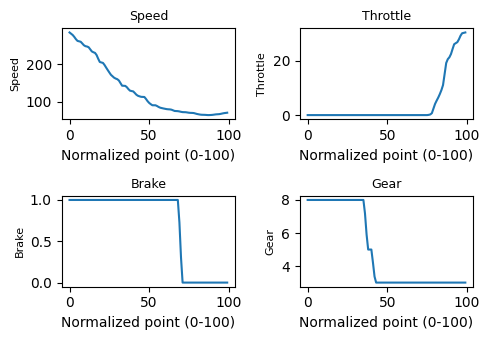

In [8]:
# Select the first sample
readAllSamples = pd.read_pickle('output/all_samples.pkl')
sample = readAllSamples.iloc[0]

# Print scalar data
print("====== Example: First Sample =======\n")
print("         == Scalar Data ==")
print(f"Session:         {sample['Year']} {sample['Race']}")
print(f"Driver:          Driver {sample['Driver']}")
print(f"Lap:             Lap {int(sample['LapNumber'])}")
print(f"Corner:          {sample['Corner']}")
print(f"Tire Compound:   {sample['TireCompound']}")
print(f"Tire Age:        {int(sample['TireAge'])} laps")
print(f"Fuel Load:       {sample['FuelLoad']:.2f} kg")

# Plot high f telem
print("\n== High-Frequency Telemetry ==")
# 4 graphs, define size
fig, axes = plt.subplots(2, 2, figsize=(5, 3.5))
channels = ['Speed', 'Throttle', 'Brake', 'Gear']

# Assign axis to channel
axesChannelPair = zip(axes.flat, channels)
for currAxis, currChannel in axesChannelPair:
    currChannelData = np.array(sample[currChannel])
    currAxis.plot(currChannelData)
    currAxis.set_title(currChannel, fontsize= 9)
    currAxis.set_xlabel('Normalized point (0-100)')
    currAxis.set_ylabel(currChannel, fontsize = 8)
plt.tight_layout()

(array([0, 1, 2]),
 [Text(0, 0, 'Hard'), Text(1, 0, 'Medium'), Text(2, 0, 'Soft')])

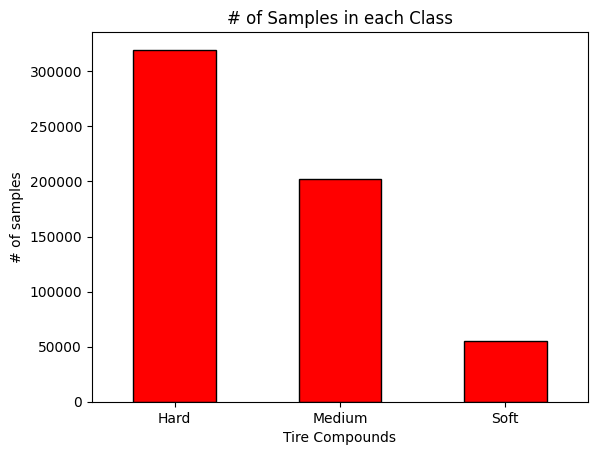

In [ ]:
# Some visual stats for progress report
combinedDF['TireCompound'].value_counts().plot(kind = 'bar', color = 'red', edgecolor = 'black') 
plt.title('# of Samples in each Class')
plt.xlabel('Tire Compounds')
plt.ylabel('# of samples')
plt.xticks(rotation=0)

## Baseline Model

In [112]:
baselineDf = pd.read_pickle('output/all_samples.pkl')
raceCompoundCounts = baselineDf.groupby(['Year', 'Race'])['TireCompound'].value_counts().unstack(fill_value=0)
print(raceCompoundCounts)

TireCompound                     Hard  Medium  Soft
Year Race                                          
2023 Abu Dhabi Grand Prix       11216    3328     0
     Australian Grand Prix       7980    1096   102
     Austrian Grand Prix         5921    4484    10
     Azerbaijan Grand Prix      10773    1985    19
     Bahrain Grand Prix          6583     107  4354
     Belgian Grand Prix           138    5774  5277
     British Grand Prix          1961    7183  3722
     Canadian Grand Prix         8235    3479    43
     Dutch Grand Prix             339    1699  6499
     Hungarian Grand Prix       10264    5539   296
     Italian Grand Prix          4563    3856     0
     Japanese Grand Prix         6796    3435   832
     Las Vegas Grand Prix        5764    1762    26
     Mexico City Grand Prix      6192    7981    48
     Miami Grand Prix           12440    4370    56
     Monaco Grand Prix           8302    5005   413
     Qatar Grand Prix            5401    6551   156
     Saudi A

**Updates From Progress Report**: Added signficantly more data and created a system to ensure the train, val, and test sets have the same class distributions. RF Model now searches for best parameters based on F1 score

In [118]:
# Helper functions

# Convert the 100 point features into useful information
# Combine all features into a new df
def baselineFeature(currRow):
    featuresDict = {}
    for channelName in ['Speed', 'Throttle', 'Brake', 'Gear']:
        # Convert to np array for easy stat functions
        channelData = np.array(currRow[channelName])
        featuresDict[f'{channelName}Mean'] = channelData.mean()
        featuresDict[f'{channelName}Min'] = channelData.min()
        featuresDict[f'{channelName}Max'] = channelData.max()
        featuresDict[f'{channelName}Std'] = channelData.std()
    # Store rest of data in the row
    featuresDict['TireAge'] = currRow['TireAge']
    featuresDict['FuelLoad'] = currRow['FuelLoad']
    featuresDict['Year'] = currRow['Year']
    featuresDict['TireCompound'] = currRow['TireCompound']

    # Needed for data split
    featuresDict['Race'] = currRow['Race']

    return pd.Series(featuresDict)

In [3]:
# ==== Split data by race and ensure each set has the same class distribution ====
combinedDf = pd.read_pickle('output/all_samples.pkl')

# Group Df by year, race and each tire compound (mandate a column order)
raceCounts = combinedDf.groupby(['Year','Race'])['TireCompound'].value_counts().unstack(fill_value = 0)
raceCounts = raceCounts.reindex(columns = ['Hard','Medium','Soft'], fill_value = 0)
raceCounts['Total'] = raceCounts.sum(axis = 1)

# Extract Year, Race pairs - needed for splitting dataset
raceList = list(raceCounts.index)

# Target distrib. each dataset should sustain
ovrDistribution = combinedDf['TireCompound'].value_counts(normalize = True)
print(f"Full Dataset Class Distribution\n{ovrDistribution}\n")

# Rnd search for race subset matching target size + class distrib
# Return yr, race identifiers of best matching data subset
def searchBalancedSplit(raceCounts, raceList, targetFrac, numTrials = 8000):
    rng = np.random.default_rng(42)

    # Determine num of target samples
    totalSamples = raceCounts['Total'].sum()
    targetSize = totalSamples * targetFrac

    # Track best subset
    bestSubset, bestScore = None, np.inf

    for _ in range(numTrials):
        # Shuffle races randomly, greedily add until close to target size
        shuffled = rng.permutation(len(raceList))
        subsetIdxes, runningTotal = [], 0
        for idx in shuffled:
            raceTotal = raceCounts.iloc[idx]['Total']
            # Check if adding one race puts us way out of range
            if runningTotal + raceTotal <= targetSize * 1.15:  # allow slight overshoot
                subsetIdxes.append(idx)
                runningTotal += raceTotal
            #  Check if the added race creates a sufficently large subset
            if runningTotal >= targetSize * 0.85:
                break

        # Safety
        if len(subsetIdxes) < 2:
            continue

        # Calc class distrib of subset
        subsetCounts = raceCounts.iloc[subsetIdxes][['Hard','Medium','Soft']].sum()
        subsetProps = subsetCounts / subsetCounts.sum()

        # Calc class distrib of rest of set (minus subset)
        remainingCounts = raceCounts.drop(raceCounts.index[subsetIdxes])[['Hard','Medium','Soft']].sum()
        remainingProps = remainingCounts / remainingCounts.sum()

        # Determine if the subset and remaining set have similar proportions
        # Use L1 distance (cheap + handles outliers well), applied element wise across the compounds then summed
        L1Dist = np.abs(subsetProps - remainingProps).sum()
        # Compare target size to subset size
        sizeScore = abs(runningTotal - targetSize) / totalSamples
        # ovr score (L1 Dist is more important)
        score = L1Dist + 0.5 * sizeScore  

        # Update best trial
        if score < bestScore:
            bestScore = score
            # Idx --> yr, race identifier
            bestSubset = [raceList[i] for i in subsetIdxes]

    return bestSubset

# Create the test, train, val datasets
# Find test set
testRaces = searchBalancedSplit(raceCounts, raceList, targetFrac = 0.15)
print(f"Test races ({len(testRaces)}): {testRaces}")

# Remove test race idx's from total
remainingRaceCounts = raceCounts.drop(index = testRaces)
remainingRaceList = list(remainingRaceCounts.index)

# Isolate val set
valRaces = searchBalancedSplit(remainingRaceCounts, remainingRaceList, targetFrac = 0.17644)  
# 0.17644 of remaining = 15% of original total
print(f"Val races ({len(valRaces)}): {valRaces}")

# Isolate train set
trainRaces = [r for r in remainingRaceList if r not in valRaces]
print(f"Train races ({len(trainRaces)})")

Full Dataset Class Distribution
TireCompound
Hard      0.553543
Medium    0.350453
Soft      0.096004
Name: proportion, dtype: float64

Test races (6): [(2023, 'Hungarian Grand Prix'), (2023, 'British Grand Prix'), (2023, 'Spanish Grand Prix'), (2024, 'Abu Dhabi Grand Prix'), (2024, 'United States Grand Prix'), (2024, 'Azerbaijan Grand Prix')]
Val races (5): [(2024, 'Emilia Romagna Grand Prix'), (2024, 'Saudi Arabian Grand Prix'), (2024, 'Spanish Grand Prix'), (2024, 'Belgian Grand Prix'), (2024, 'Mexico City Grand Prix')]
Train races (34)


In [119]:
# Build the Dfs
testSet = set(testRaces)
valSet = set(valRaces)

# Find which Year, Race pairs are in test/val sets
yearRacePairs = list(zip(combinedDf['Year'], combinedDf['Race']))
isTest = pd.Series(yearRacePairs, index = combinedDf.index).isin(testSet)
isVal = pd.Series(yearRacePairs, index = combinedDf.index).isin(valSet)

# Use masks to create final dataframes
testDf = combinedDf[isTest].reset_index(drop = True)
valDf = combinedDf[isVal].reset_index(drop = True)
trainDf = combinedDf[~isTest & ~isVal].reset_index(drop = True)

print(f"Train Samples: {len(trainDf)}")
print(f"Validation Samples: {len(valDf)}")
print(f"Test Samples: {len(testDf)}")

# Verify the proportions worked in the final Dfs
for name, df in [('Train', trainDf), ('Val', valDf), ('Test', testDf)]:
    print(f"\n{name} distribution:\n{df['TireCompound'].value_counts(normalize = True)}")

Train Samples: 410656
Validation Samples: 81033
Test Samples: 85735

Train distribution:
TireCompound
Hard      0.553502
Medium    0.350327
Soft      0.096171
Name: proportion, dtype: float64

Val distribution:
TireCompound
Hard      0.553688
Medium    0.349882
Soft      0.096430
Name: proportion, dtype: float64

Test distribution:
TireCompound
Hard      0.553601
Medium    0.351595
Soft      0.094804
Name: proportion, dtype: float64


In [120]:
# Extract features for each data set
trainFeatDf = trainDf.apply(baselineFeature, axis = 1)
valFeatDf = valDf.apply(baselineFeature, axis = 1)
testFeatDf = testDf.apply(baselineFeature, axis = 1)

print(f"Train features: {trainFeatDf.shape}, Val: {valFeatDf.shape}, Test: {testFeatDf.shape}")

# Split extraneous vals and ground truth cols
extraCols = ['Year', 'Race', 'TireCompound']
featureCols = [c for c in trainFeatDf.columns if c not in extraCols]

# Define model in/out from dataset
trainIn, trainTarg = trainFeatDf[featureCols], trainFeatDf['TireCompound']
valIn, valTarg = valFeatDf[featureCols], valFeatDf['TireCompound']
testIn, testTarg = testFeatDf[featureCols], testFeatDf['TireCompound']

Train features: (410656, 21), Val: (81033, 21), Test: (85735, 21)


In [ ]:
# Randomized Search RF to find best params
paramOptions = {
    'n_estimators': [200, 400, 600],
    'max_depth': [10, 15, 20, None],
    'min_samples_leaf': [1, 3, 5, 10],
    'max_features': ['sqrt', 'log2', 0.5],
}
baselineModel = RandomizedSearchCV(
    RandomForestClassifier(class_weight = 'balanced', random_state = 42, n_jobs = -1),
    paramOptions, n_iter = 30, scoring = make_scorer(f1_score, average = 'macro'),
    cv = 3, n_jobs = -1, random_state = 42
)
baselineModel.fit(trainIn, trainTarg)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'max_depth': [10, 15, ...], 'max_features': ['sqrt', 'log2', ...], 'min_samples_leaf': [1, 3, ...], 'n_estimators': [200, 400, ...]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",make_scorer(f...average=macro)
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSear

In [29]:
# Validation Set Evaluation

# == 1) Quantitative Results ==
baseValPred = baselineModel.predict(valIn)

#  Raw prediction accuracy
print(f"\nAccuracy: {accuracy_score(valTarg, baseValPred):.3f}")

# Precision, recall, and F1 
print("\nClassification report:")
allTireComps = set(baselineDf['TireCompound'].unique())
print(classification_report(valTarg, baseValPred, labels = sorted(allTireComps)))

# Confusion matrix
print("Confusion Matrix")
print(confusion_matrix(valTarg, baseValPred, labels = sorted(allTireComps)))
# For ease of reading
print(f"Labels order: {sorted(allTireComps)}")

# == 2) Qualitative results == 
importances = pd.Series(baselineModel.feature_importances_, index = featureCols).sort_values(ascending=False)
print("\n\nTop 10 Feature Importances")
print(importances.head(10))



Accuracy: 0.625

Classification report:
              precision    recall  f1-score   support

        Hard       0.74      0.76      0.75     44867
      Medium       0.60      0.46      0.52     28352
        Soft       0.28      0.48      0.36      7814

    accuracy                           0.63     81033
   macro avg       0.54      0.57      0.54     81033
weighted avg       0.65      0.63      0.63     81033

Confusion Matrix
[[33885  5990  4992]
 [10690 13007  4655]
 [ 1502  2526  3786]]
Labels order: ['Hard', 'Medium', 'Soft']


AttributeError: 'RandomizedSearchCV' object has no attribute 'feature_importances_'

In [ ]:
# Re running features importances on a hardcoded RF using the optimized RF found in the random search
# The weights are from the RF module that shows up on VSCode and explains what the best weights it found were
baselineModelHardcode = RandomForestClassifier(class_weight='balanced', max_depth=15, max_features=0.5,
                       min_samples_leaf=3, n_estimators=400, n_jobs=-1,
                       random_state=42)
baselineModelHardcode.fit(trainIn, trainTarg)
baseValPred = baselineModelHardcode.predict(valIn)

# == 2) Qualitative results == 
importances = pd.Series(baselineModelHardcode.feature_importances_, index = featureCols).sort_values(ascending=False)
print("\n\nTop 10 Feature Importances")
print(importances.head(10))



Top 10 Feature Importances
FuelLoad        0.293977
TireAge         0.179481
SpeedMin        0.081120
SpeedMean       0.063342
SpeedStd        0.060840
SpeedMax        0.059243
ThrottleStd     0.044159
ThrottleMean    0.041787
GearMean        0.036236
GearStd         0.030502
dtype: float64


In [124]:
# Test Set Evaluation
# == 1) Quantitative Results ==
baseTestPred = baselineModelHardcode.predict(testIn)

#  Raw prediction accuracy
print(f"\nAccuracy: {accuracy_score(testTarg, baseTestPred):.3f}")

# Precision, recall, and F1 
print("\nClassification report:")
allTireComps = set(baselineDf['TireCompound'].unique())
print(classification_report(testTarg, baseTestPred, labels = sorted(allTireComps)))

# Confusion matrix
print("Confusion Matrix")
print(confusion_matrix(testTarg, baseTestPred, labels = sorted(allTireComps)))
# For ease of reading
print(f"Labels order: {sorted(allTireComps)}")


Accuracy: 0.645

Classification report:
              precision    recall  f1-score   support

        Hard       0.76      0.77      0.76     47463
      Medium       0.60      0.50      0.55     30144
        Soft       0.29      0.45      0.35      8128

    accuracy                           0.64     85735
   macro avg       0.55      0.57      0.55     85735
weighted avg       0.66      0.64      0.65     85735

Confusion Matrix
[[36471  7484  3508]
 [ 9700 15143  5301]
 [ 2001  2484  3643]]
Labels order: ['Hard', 'Medium', 'Soft']


Overall, the Baseline Model shows signficant improvement in Accuracy and F1 score from the initial baseline from the progress report. However, the models overall performance is still poor. The baseline shows that the NN portion might be feasible, but investing more time in a model of this size is not worth it. The added temporal context and data volume for the NN portion should result in improvements.

## Primary Neural Network Model

### NN Declarations and Preparation

In [34]:
# Read all samples
nnDF = pd.read_pickle('output/all_samples.pkl')

In [35]:
# Define test, val, train sets (same as baseline)
testSet = set(testRaces)
valSet = set(valRaces)

yearRacePairsNN = list(zip(nnDF['Year'], nnDF['Race']))
isTestNN = pd.Series(yearRacePairsNN, index = nnDF.index).isin(testSet)
isValNN = pd.Series(yearRacePairsNN, index = nnDF.index).isin(valSet)

nnTestDF = nnDF[isTestNN].reset_index(drop = True)
nnValDF = nnDF[isValNN].reset_index(drop = True)
nnTrainDF = nnDF[~isTestNN & ~isValNN].reset_index(drop = True)

print(f"Train Samples: {len(nnTrainDF)}")
print(f"Validation Samples: {len(nnValDF)}")
print(f"Test Samples: {len(nnTestDF)}")

# Verify distribution
for name, df in [('Train', nnTrainDF), ('Val', nnValDF), ('Test', nnTestDF)]:
    print(f"\n{name} distribution:\n{df['TireCompound'].value_counts(normalize = True)}")

Train Samples: 410656
Validation Samples: 81033
Test Samples: 85735

Train distribution:
TireCompound
Hard      0.553502
Medium    0.350327
Soft      0.096171
Name: proportion, dtype: float64

Val distribution:
TireCompound
Hard      0.553688
Medium    0.349882
Soft      0.096430
Name: proportion, dtype: float64

Test distribution:
TireCompound
Hard      0.553601
Medium    0.351595
Soft      0.094804
Name: proportion, dtype: float64


In [ ]:
# Calculate Avg values for normalization
maxSpeed = nnDF['Speed'].map(max).max()
maxThrottle = nnDF['Throttle'].map(max).max()
maxGear = nnDF['Gear'].map(max).max()
maxFuelLoad = nnDF['FuelLoad'].max()
maxTireAge = nnDF['TireAge'].max()

# Create a subclass of Dataset for custom DataLoading logic
class TelemetryDataset(Dataset):

    # Called internally to determine num samples
    def __len__(self):
        return len(self.df)
    
    # Constructor, stores df and fixes index
    def __init__(self, df):
        self.df = df.reset_index(drop = True)

    # Gets 1 training sample of row idx
    def __getitem__(self, idx):
        currRow = self.df.iloc[idx]
        # Stack and normalize data samples 
        # Ensure dtype matches what NN expects
        mergeData = np.stack([
            np.array(currRow['Speed'], dtype = np.float32) / maxSpeed,
            np.array(currRow['Throttle'], dtype = np.float32) / maxThrottle,
            np.array(currRow['Gear'], dtype = np.float32) / maxGear,
            np.array(currRow['Brake'], dtype = np.float32), # Binary already
        ])
        # Isolate and return sample and lebel (expected from this function)
        sample = torch.from_numpy(mergeData.astype(np.float32))
        # convert static feats to tensor
        staticFeats = torch.tensor(
            [currRow['FuelLoad'] / maxFuelLoad, 
             currRow['TireAge'] / maxTireAge],
            dtype = torch.float32
        )
        label = compToIdx[currRow['TireCompound']]
        return sample, label, staticFeats

In [37]:
# Load data (adapted from my Lab 4 code)
def loadData(batchSize):
    trainLoader = DataLoader(TelemetryDataset(nnTrainDF), batch_size = batchSize, shuffle =True)
    valLoader = DataLoader(TelemetryDataset(nnValDF), batch_size = batchSize, shuffle = False)
    testLoader = DataLoader(TelemetryDataset(nnTestDF), batch_size = batchSize, shuffle = False)
    return trainLoader, valLoader, testLoader

In [ ]:
# Define initial CNN + LSTM + final FCN layer structure for early testing
class PrimaryModel(nn.Module):
    # Use parameters in defn for easy editing later
    def __init__(self, numClasses = 3, cnnChannels = 16, lstmHidden = 32, numStaticFeats = 2, dropoutP = 0.3):
        super(PrimaryModel, self).__init__()
        self.name = "PrimaryModel"
        # Conv Part
        self.conv1 = nn.Conv1d(in_channels = 4, out_channels = cnnChannels, kernel_size = 5, padding = 2)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool1d(kernel_size = 2)

        # LSTM Part
        self.lstm = nn.LSTM(input_size = cnnChannels, hidden_size = lstmHidden, batch_first = True)
        self.dropout = nn.Dropout(dropoutP)
        self.fc = nn.Linear(lstmHidden + numStaticFeats, numClasses)

    def forward(self, x, staticFeats):
        x = self.pool(self.relu(self.conv1(x)))
        x = x.permute(0, 2, 1) # LSTM needs (batch, seq, chans) so swap order
        _, (hidden, _) = self.lstm(x) # only need hidden part
        # Concatenate fuel load and tire age
        addStaticFeats = torch.cat([hidden[-1], staticFeats], dim=1) # remove unneeded dim
        dropoutLayer = self.dropout(addStaticFeats)
        return self.fc(dropoutLayer) 

### NN Training

In [ ]:
# Relevant code is adapted from course Labs 1 - 4
def get_model_name(name, batch_size, learning_rate, epoch):
    return "model_{0}_bs{1}_lr{2}_epoch{3}".format(name, batch_size, learning_rate, epoch)

# returns percent correct predictions and macro F1
def getAccuracy(model, loader):
    model.eval() # switch to eval mode
    correct, total = 0, 0
    allPreds, allLabels = [], [] # For f1 score
    with torch.no_grad():
        for tel, labels, staticFeats in loader:
            # Predict and isolate highest prob. class
            pred = torch.argmax(model(tel, staticFeats), dim = 1)
            correct += (pred == labels).sum().item()
            total += labels.size(0) # total samples
            # Add curr preds/labels
            allPreds.extend(pred.tolist())
            allLabels.extend(labels.tolist())
    model.train() # switch back to train mode
    # Calc F1 Score
    macroF1 = f1_score(allLabels, allPreds, average = 'macro')
    return correct / total, macroF1

def train(model, trainLoader, valLoader, numEpochs = 25, learningRate = 0.001, batchSize = 32, classWeights = None, weightDecay = 0.0, earlyStopEpochs = 4):
    torch.manual_seed(42)
    criterion = nn.CrossEntropyLoss(weight = classWeights)
    # If weight decay given use different optim
    if (weightDecay != 0.0):
        optimizer = torch.optim.AdamW(model.parameters(), lr = learningRate, weight_decay = weightDecay) 
    else:
       optimizer = torch.optim.Adam(model.parameters(), lr = learningRate)
    
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode = 'min', factor = 0.5, patience = 2)

    # Init stat lists
    trainLoss = np.zeros(numEpochs)
    valLoss = np.zeros(numEpochs)
    trainAcc = np.zeros(numEpochs)
    valAcc = np.zeros(numEpochs)
    valF1 = np.zeros(numEpochs)

    # Track best values + f1 improvement stall
    bestValF1 = -np.inf
    bestEpoch = -1
    numStalledF1 = 0
    lastEpoch = numEpochs - 1

    for epoch in range(numEpochs):
        model.train() # activate train mode
        epochLoss = 0
        for tel, labels, staticFeats in trainLoader:
            optimizer.zero_grad()
            outputs = model(tel, staticFeats)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            epochLoss += loss.item()
        trainLoss[epoch] = epochLoss / len(trainLoader)
        trainAcc[epoch], _ = getAccuracy(model, trainLoader)

        model.eval() # switch to eval mode
        with torch.no_grad():
            valLoss[epoch] = sum(criterion(model(tel, staticFeats), labels).item() for tel, labels, staticFeats in valLoader) / len(valLoader)
        valAcc[epoch], valF1[epoch] = getAccuracy(model, valLoader)

        scheduler.step(valLoss[epoch])

        print(f"Epoch {epoch + 1}: Train Loss: {trainLoss[epoch]:.5f} Train Accuracy: {trainAcc[epoch]:.5f} "
              f"Val. Loss: {valLoss[epoch]:.5f} Val Acc: {valAcc[epoch]:.5f} Val Macro F1: {valF1[epoch]:.5f}")

        if epoch % 5 == 0 or epoch == numEpochs - 1:
            torch.save(model.state_dict(), "ModelSaves/" + get_model_name(model.name, batchSize, learningRate, epoch))

        # Seperately track best val loss and checkpoint
        if valF1[epoch] > bestValF1:
            bestValF1 = valF1[epoch]
            bestEpoch = epoch
            numStalledF1 = 0
            torch.save(model.state_dict(), "ModelSaves/" + model.name + "_bestValF1")
        else:
            numStalledF1 += 1
            if numStalledF1 >= earlyStopEpochs:
                print(f"Stopping at {epoch + 1} due to no improvements for {earlyStopEpochs} epochs\n")
                lastEpoch = epoch
                trainAcc, trainLoss = trainAcc[:lastEpoch+1], trainLoss[:lastEpoch+1]
                valAcc, valLoss, valF1 = valAcc[:lastEpoch+1], valLoss[:lastEpoch+1], valF1[:lastEpoch+1]

                break

    print(f"\nBest epoch: {bestEpoch + 1} (Val F1: {bestValF1:.5f})")
    return trainAcc, trainLoss, valAcc, valLoss, valF1

def plot_training_curve(train_acc, train_loss, val_acc, val_loss):
    # Loss plot
    plt.title("Train & Validation Loss")
    plt.plot(train_loss, label = "Train") 
    plt.plot(val_loss, label = "Val")
    plt.xlabel("Epoch")
    plt.ylabel("Loss") 
    plt.legend()
    plt.show()

    # Accuracy plot
    plt.title("Train & Validation Accuracy")
    plt.plot(train_acc, label = "Train")
    plt.plot(val_acc, label = "Val")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy") 
    plt.legend()
    plt.show()

# Convert labels to num and vice versa
compToIdx = {'Hard': 0, 'Medium': 1, 'Soft': 2}
idxToComp = {v: k for k, v in compToIdx.items()}

In [41]:
# Compute class weights from the training set (scarcity priority order)
# Convert labels from English to Index, find the counts of each class
classCounts = nnTrainDF['TireCompound'].map(compToIdx).value_counts().sort_index()
# Find total samples and # classes for formula
totalSamples = classCounts.sum()
numClasses = len(compToIdx)
rawWeightFormula = totalSamples / (numClasses * classCounts)

# Loop through each class and apply the formula
# Convert tensor for CrossEntropyLoss
classWeights = torch.tensor((rawWeightFormula ** 0.5).values, dtype=torch.float32)
print("Class weights (Hard, Medium, Soft):", classWeights)

Class weights (Hard, Medium, Soft): tensor([0.7760, 0.9754, 1.8617])


In [ ]:
# Trial 0
# batch_size = 32, lr = 0.001, first epoch
# Training code for this has been overwritten during testing but the model itself is saved
inspectModel = PrimaryModel()
inspectModel.load_state_dict(torch.load("ModelSaves/model_PrimaryModel_bs32_lr0.001_epoch0"))
inspectModel.eval()

_, valLoader0, _ = loadData(32)

allPreds, allLabels = [], []
with torch.no_grad():
    for tel, labels, staticFeats in valLoader0:
        preds = torch.argmax(inspectModel(tel, staticFeats), dim = 1)
        allPreds.extend(preds.tolist())
        allLabels.extend(labels.tolist())

print(classification_report(allLabels, allPreds, target_names = ['Hard', 'Medium', 'Soft']))
print(confusion_matrix(allLabels, allPreds))

Epoch 1: Train Loss: 1.01713 Train Accuracy: 0.60449 Val. Loss: 0.91634 Val Acc: 0.61154 Val Macro F1: 0.38373
Epoch 2: Train Loss: 1.01285 Train Accuracy: 0.59988 Val. Loss: 0.91575 Val Acc: 0.60902 Val Macro F1: 0.38394
Epoch 3: Train Loss: 1.00883 Train Accuracy: 0.59680 Val. Loss: 0.91910 Val Acc: 0.60780 Val Macro F1: 0.40062
Epoch 4: Train Loss: 1.00260 Train Accuracy: 0.58765 Val. Loss: 0.92546 Val Acc: 0.59814 Val Macro F1: 0.41200
Epoch 5: Train Loss: 0.99372 Train Accuracy: 0.59597 Val. Loss: 0.92166 Val Acc: 0.59666 Val Macro F1: 0.40028
Epoch 6: Train Loss: 0.98053 Train Accuracy: 0.59052 Val. Loss: 0.93473 Val Acc: 0.57250 Val Macro F1: 0.41043
Epoch 7: Train Loss: 0.97380 Train Accuracy: 0.59404 Val. Loss: 0.93394 Val Acc: 0.57958 Val Macro F1: 0.40342
Epoch 8: Train Loss: 0.97028 Train Accuracy: 0.59590 Val. Loss: 0.93488 Val Acc: 0.57370 Val Macro F1: 0.40112
Epoch 9: Train Loss: 0.96356 Train Accuracy: 0.59667 Val. Loss: 0.93900 Val Acc: 0.57078 Val Macro F1: 0.39956
E

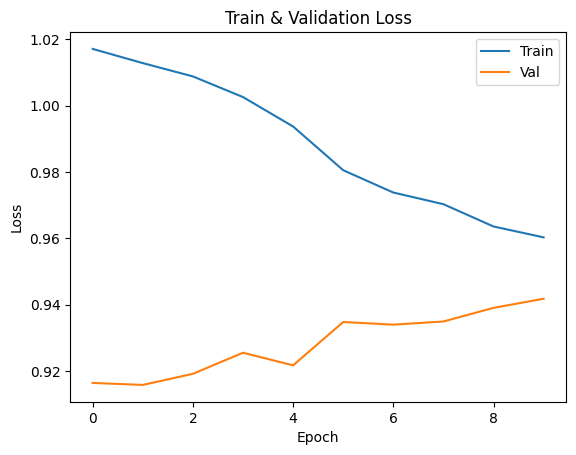

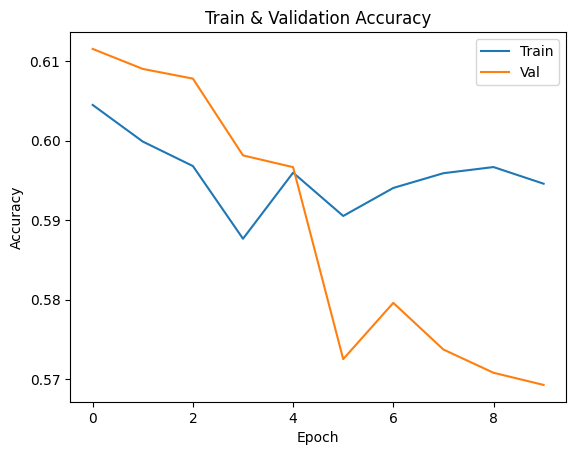

In [ ]:
# Trial 1 
# numEpochs = 10, learningRate = 0.003, batchSize = 128, class weights active
# Previous trial justifies the need for a more aggressive learning rate and a larger batch size (large dataset, 32 is relatively small)
trainLoader, valLoader, testLoader = loadData(128)
primaryModel = PrimaryModel()
trainAcc, trainLoss, valAcc, valLoss, valF1 = train(primaryModel, trainLoader, valLoader, numEpochs = 10, learningRate = 0.003, batchSize = 128, classWeights = classWeights)
plot_training_curve(trainAcc, trainLoss, valAcc, valLoss)

In [ ]:
# Trial 1 Model Analysis
inspectModel = PrimaryModel()
inspectModel.load_state_dict(torch.load("ModelSaves/model_PrimaryModel_bs128_lr0.003_epoch5"))
inspectModel.eval()

allPreds, allLabels = [], []
with torch.no_grad():
    for tel, labels, staticFeats in valLoader:
        preds = torch.argmax(inspectModel(tel, staticFeats), dim = 1)
        allPreds.extend(preds.tolist())
        allLabels.extend(labels.tolist())

print(classification_report(allLabels, allPreds, target_names = ['Hard', 'Medium', 'Soft']))
print(confusion_matrix(allLabels, allPreds))

              precision    recall  f1-score   support

        Hard       0.64      0.77      0.70     44867
      Medium       0.52      0.39      0.44     28352
        Soft       0.11      0.07      0.09      7814

    accuracy                           0.57     81033
   macro avg       0.42      0.41      0.41     81033
weighted avg       0.54      0.57      0.55     81033

[[34754  7589  2524]
 [15368 11076  1908]
 [ 4476  2777   561]]


In [ ]:
# The previous trial shows a consistently poor F1 score, going to test oversampling since it physically 
# changes the models data input instead of rescaling the scores
# Determines how each class should be sampled
sampleWeights = nnTrainDF['TireCompound'].map(compToIdx).map(
    {classIdx: weight.item() for classIdx, weight in enumerate(classWeights)}
).values

# Samples based on above weights
sampler = WeightedRandomSampler(sampleWeights, num_samples = len(sampleWeights), replacement = True)

# Load training set based on sampler
trainLoaderWeighted = DataLoader(TelemetryDataset(nnTrainDF), batch_size = 128, sampler = sampler)
_, valLoader, testLoader = loadData(128)

Epoch 1: Train Loss: 1.01779 Train Accuracy: 0.51331 Val. Loss: 0.91032 Val Acc: 0.60793 Val Macro F1: 0.37999
Epoch 2: Train Loss: 1.01467 Train Accuracy: 0.51717 Val. Loss: 0.90931 Val Acc: 0.60896 Val Macro F1: 0.40625
Epoch 3: Train Loss: 1.00797 Train Accuracy: 0.51849 Val. Loss: 0.91130 Val Acc: 0.61086 Val Macro F1: 0.39503
Epoch 4: Train Loss: 0.99838 Train Accuracy: 0.52414 Val. Loss: 0.91568 Val Acc: 0.58776 Val Macro F1: 0.40989
Epoch 5: Train Loss: 0.98876 Train Accuracy: 0.52417 Val. Loss: 0.91231 Val Acc: 0.58867 Val Macro F1: 0.41465
Epoch 6: Train Loss: 0.97713 Train Accuracy: 0.53035 Val. Loss: 0.91704 Val Acc: 0.57595 Val Macro F1: 0.41334
Epoch 7: Train Loss: 0.97261 Train Accuracy: 0.53712 Val. Loss: 0.92889 Val Acc: 0.56905 Val Macro F1: 0.42220
Epoch 8: Train Loss: 0.96853 Train Accuracy: 0.53849 Val. Loss: 0.92403 Val Acc: 0.57254 Val Macro F1: 0.40626
Epoch 9: Train Loss: 0.96043 Train Accuracy: 0.53852 Val. Loss: 0.93648 Val Acc: 0.56323 Val Macro F1: 0.41110
E

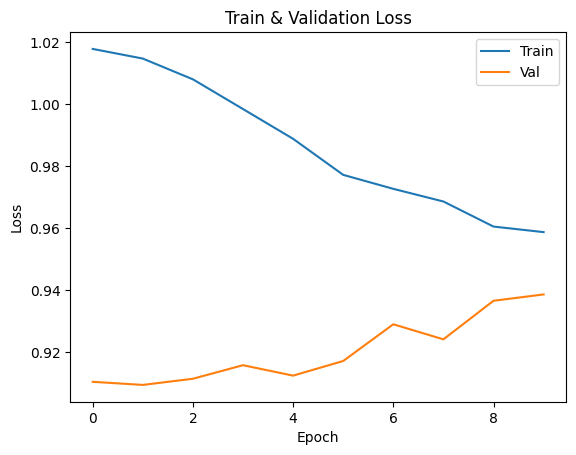

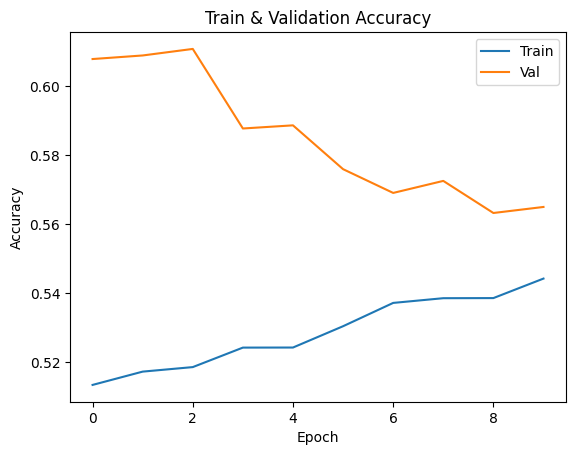

In [ ]:
# Trial 2 
# numEpochs = 10, learningRate = 0.003, batchSize = 128
primaryModel = PrimaryModel()
trainAcc, trainLoss, valAcc, valLoss, valF1 = train(primaryModel, trainLoaderWeighted, valLoader, numEpochs = 10, learningRate = 0.003, batchSize = 128)
plot_training_curve(trainAcc, trainLoss, valAcc, valLoss)

In [ ]:
# Trial 2 Model Analysis
primaryModel.eval()
allPreds, allLabels = [], []
with torch.no_grad():
    for tel, labels, staticFeats in valLoader:
        preds = torch.argmax(primaryModel(tel, staticFeats), dim=1)
        allPreds.extend(preds.tolist())
        allLabels.extend(labels.tolist())

print(classification_report(allLabels, allPreds, target_names = ['Hard', 'Medium', 'Soft']))
print(confusion_matrix(allLabels, allPreds))
print(f"Labels order: ['Hard', 'Medium', 'Soft']")

              precision    recall  f1-score   support

        Hard       0.63      0.80      0.70     44867
      Medium       0.52      0.32      0.40     28352
        Soft       0.12      0.11      0.11      7814

    accuracy                           0.56     81033
   macro avg       0.43      0.41      0.41     81033
weighted avg       0.54      0.56      0.54     81033

[[35781  5837  3249]
 [16522  9174  2656]
 [ 4504  2483   827]]
Labels order: ['Hard', 'Medium', 'Soft']


In [ ]:
# Primary Model plateaus still; going to test more capacity (number of parameters relative to datasize/style is too small)
# Larger model - more capacity, BiLSTM 
class SecondModel(nn.Module):
    # Doubled CNN channels and LSTM hidden units
    def __init__(self, numClasses = 3, cnnChannels = 32, lstmHidden = 64, numStaticFeats = 2, dropoutP = 0.3):
        super(SecondModel, self).__init__()
        self.name = "SecondModel"

        self.conv1 = nn.Conv1d(in_channels = 4, out_channels = cnnChannels, kernel_size = 5, padding = 2)
        # Added BN on conv output to incr. lr (more stable)
        self.bn1 = nn.BatchNorm1d(cnnChannels)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool1d(kernel_size = 2)

        # BiLSTM - model can better understand behaviour if it can look in both direc.
        self.lstm = nn.LSTM(input_size = cnnChannels, hidden_size = lstmHidden, batch_first = True, bidirectional = True)
        lstmOutDim = lstmHidden * 2  # bidirec. doubles it

        # Give FuelLoad/TireAge own small nonlin branch
        # Increases their representationn vs. the telem outputs
        self.staticBranch = nn.Sequential(
            nn.Linear(numStaticFeats, 16),
            nn.ReLU(),
            nn.Linear(16, 16),
            nn.ReLU(),
        )

        # Dropout
        self.dropout = nn.Dropout(dropoutP)

        # Final run with static + telem
        self.head = nn.Sequential(
            nn.Linear(lstmOutDim + 16, 64),
            nn.ReLU(),
            nn.Dropout(dropoutP),
            nn.Linear(64, numClasses),
        )

    def forward(self, x, staticFeats):
        x = self.pool(self.relu(self.bn1(self.conv1(x))))
        x = x.permute(0, 2, 1)
        _, (hidden, _) = self.lstm(x)
        # bidirec, concat forward + backward final hidden states
        hiddenCat = torch.cat([hidden[-2], hidden[-1]], dim=1)
        # Static data through own branch
        staticEmbed = self.staticBranch(staticFeats)
        # Combine static + telem, do droput then head
        combined = torch.cat([hiddenCat, staticEmbed], dim=1)
        combined = self.dropout(combined)
        return self.head(combined)

Epoch 1: Train Loss: 0.90554 Train Accuracy: 0.61495 Val. Loss: 0.78494 Val Acc: 0.64850 Val Macro F1: 0.54431
Epoch 2: Train Loss: 0.86661 Train Accuracy: 0.62731 Val. Loss: 0.80362 Val Acc: 0.63888 Val Macro F1: 0.52130
Epoch 3: Train Loss: 0.84537 Train Accuracy: 0.63649 Val. Loss: 0.82863 Val Acc: 0.62808 Val Macro F1: 0.51700
Epoch 4: Train Loss: 0.83068 Train Accuracy: 0.64490 Val. Loss: 0.84557 Val Acc: 0.63448 Val Macro F1: 0.52650
Epoch 5: Train Loss: 0.81016 Train Accuracy: 0.65529 Val. Loss: 0.84093 Val Acc: 0.63119 Val Macro F1: 0.51994

Best epoch: 3 (Val Loss: 0.51700)


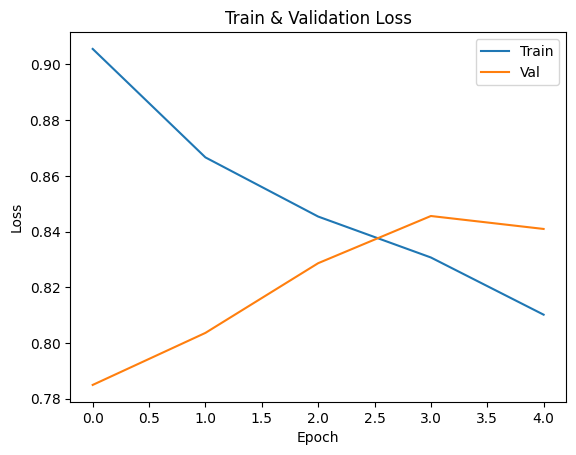

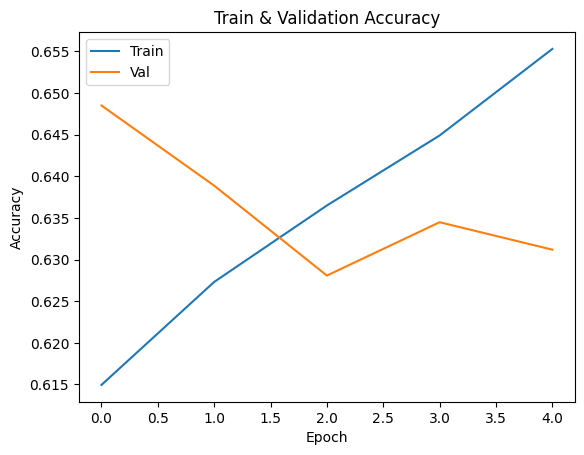

In [ ]:
# Trial 3 
# numEpochs = 5, learningRate = 0.003, batchSize = 128
# Larger model, rest of the params. are the same to test the effect of more capacity
trial3Model = SecondModel()
trainAcc, trainLoss, valAcc, valLoss, valF1 = train(trial3Model, trainLoaderWeighted, valLoader, numEpochs = 5, learningRate = 0.003, batchSize = 128)
plot_training_curve(trainAcc, trainLoss, valAcc, valLoss)

In [ ]:
# Trial 3 Model Analysis
inspectModel3 = SecondModel()
inspectModel3.load_state_dict(torch.load("ModelSaves/model_SecondModel_bs128_lr0.003_epoch0"))
inspectModel3.eval()

allPreds, allLabels = [], []
with torch.no_grad():
    for tel, labels, staticFeats in valLoader:
        preds = torch.argmax(inspectModel3(tel, staticFeats), dim=1)
        allPreds.extend(preds.tolist())
        allLabels.extend(labels.tolist())

print("Trial 3 Classification Report + Confusion Matrix")
print(classification_report(allLabels, allPreds, target_names = ['Hard', 'Medium', 'Soft']))
print(confusion_matrix(allLabels, allPreds))

Trial 3 Classification Report + Confusion Matrix
              precision    recall  f1-score   support

        Hard       0.72      0.80      0.76     44867
      Medium       0.62      0.50      0.55     28352
        Soft       0.30      0.34      0.32      7814

    accuracy                           0.65     81033
   macro avg       0.55      0.55      0.54     81033
weighted avg       0.65      0.65      0.64     81033

[[35752  5434  3681]
 [11811 14128  2413]
 [ 2065  3079  2670]]


Epoch 1: Train Loss: 0.89647 Train Accuracy: 0.61824 Val. Loss: 0.77661 Val Acc: 0.65044 Val Macro F1: 0.52860
Epoch 2: Train Loss: 0.85265 Train Accuracy: 0.63039 Val. Loss: 0.79327 Val Acc: 0.62994 Val Macro F1: 0.51289
Epoch 3: Train Loss: 0.83282 Train Accuracy: 0.63682 Val. Loss: 0.79682 Val Acc: 0.63148 Val Macro F1: 0.51381
Epoch 4: Train Loss: 0.81665 Train Accuracy: 0.64728 Val. Loss: 0.80412 Val Acc: 0.64527 Val Macro F1: 0.53021
Epoch 5: Train Loss: 0.79616 Train Accuracy: 0.65825 Val. Loss: 0.81371 Val Acc: 0.63690 Val Macro F1: 0.51882
Epoch 6: Train Loss: 0.78852 Train Accuracy: 0.65888 Val. Loss: 0.81277 Val Acc: 0.64287 Val Macro F1: 0.51891
Epoch 7: Train Loss: 0.77899 Train Accuracy: 0.66420 Val. Loss: 0.81816 Val Acc: 0.63885 Val Macro F1: 0.51860
Epoch 8: Train Loss: 0.76809 Train Accuracy: 0.67029 Val. Loss: 0.82807 Val Acc: 0.63778 Val Macro F1: 0.51446
Epoch 9: Train Loss: 0.76216 Train Accuracy: 0.67108 Val. Loss: 0.84162 Val Acc: 0.63433 Val Macro F1: 0.51451
E

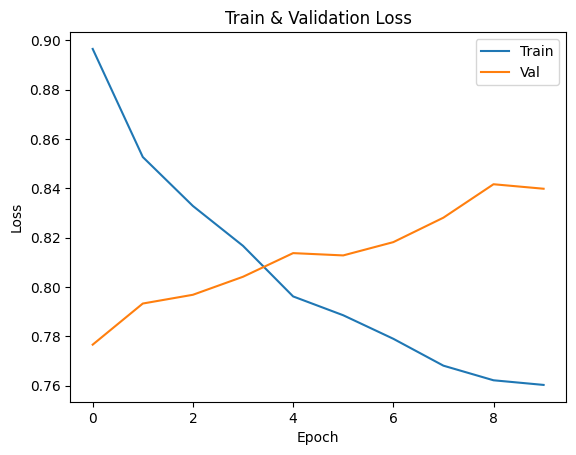

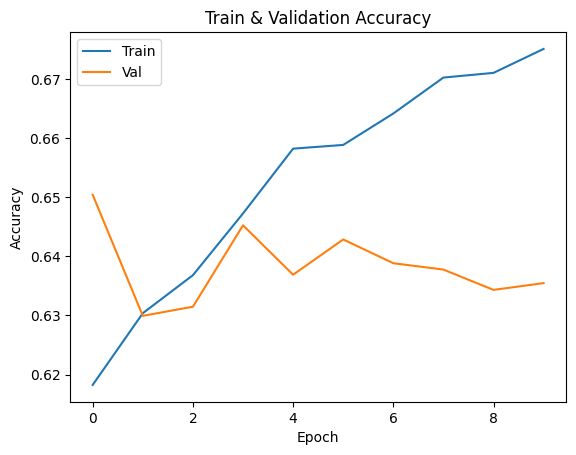

In [ ]:
# Trial 4
# The larger model shows signficant improvement to both the accuracy and F1
# Signs of quick overfitting and instability are still present, going to try adding weight decay
# numEpochs = 10, learningRate = 0.003, batchSize = 128, weightDecay = 1e-4
trial4Model = SecondModel()
trial4Model.name = "SecondModel_wd1e-4"
trainAcc, trainLoss, valAcc, valLoss, valF1 = train(trial4Model, trainLoaderWeighted, valLoader, 
                                                    numEpochs = 10, learningRate = 0.003, batchSize = 128, weightDecay = 1e-4)
plot_training_curve(trainAcc, trainLoss, valAcc, valLoss)

In [ ]:
# Trial 4 Model Analysis
inspectModel4 = SecondModel()
inspectModel4.load_state_dict(torch.load("ModelSaves/model_SecondModel_wd1e-4_bs128_lr0.003_epoch0"))
inspectModel4.eval()

allPreds, allLabels = [], []
with torch.no_grad():
    for tel, labels, staticFeats in valLoader:
        preds = torch.argmax(inspectModel4(tel, staticFeats), dim=1)
        allPreds.extend(preds.tolist())
        allLabels.extend(labels.tolist())

print("Trial 4 Classification Report + Confusion Matrix")
print(classification_report(allLabels, allPreds, target_names = ['Hard', 'Medium', 'Soft']))
print(confusion_matrix(allLabels, allPreds))

Trial 4 Classification Report + Confusion Matrix
              precision    recall  f1-score   support

        Hard       0.71      0.82      0.76     44867
      Medium       0.63      0.50      0.56     28352
        Soft       0.28      0.26      0.27      7814

    accuracy                           0.65     81033
   macro avg       0.54      0.52      0.53     81033
weighted avg       0.64      0.65      0.64     81033

[[36574  5046  3247]
 [12362 14111  1879]
 [ 2632  3160  2022]]


Epoch 1: Train Loss: 0.90547 Train Accuracy: 0.61303 Val. Loss: 0.77972 Val Acc: 0.64891 Val Macro F1: 0.54281
Epoch 2: Train Loss: 0.86317 Train Accuracy: 0.62710 Val. Loss: 0.79510 Val Acc: 0.64107 Val Macro F1: 0.52289
Epoch 3: Train Loss: 0.84310 Train Accuracy: 0.63689 Val. Loss: 0.80801 Val Acc: 0.63821 Val Macro F1: 0.52066
Epoch 4: Train Loss: 0.82769 Train Accuracy: 0.63386 Val. Loss: 0.77939 Val Acc: 0.65628 Val Macro F1: 0.52079
Epoch 5: Train Loss: 0.81563 Train Accuracy: 0.64133 Val. Loss: 0.80320 Val Acc: 0.65099 Val Macro F1: 0.51512
Stopping at 5 due to no improvements for 4 epochs


Best epoch: 1 (Val F1: 0.54281)


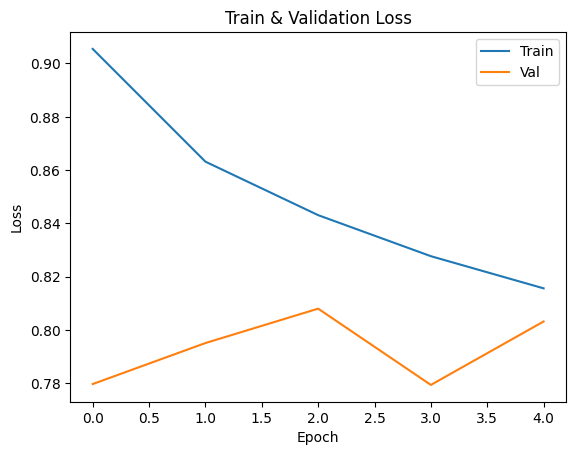

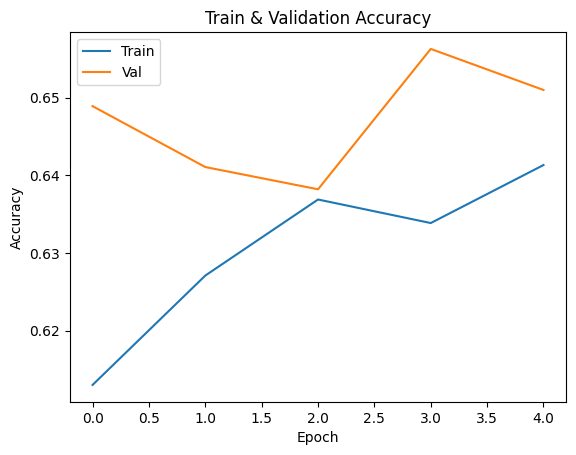

In [ ]:
# Trial 5
# numEpochs = 20, learningRate=0.003, batchSize=128, weightDecay = 1e-4
# Best setup yet; Run more epochs to analyze the extent of overfitting and if Macro F1 might improve
trial5Model = SecondModel()
trial5Model.name = "SecondModel_wd1e-4_v2"
trainAcc, trainLoss, valAcc, valLoss, valF1 = train(trial5Model, trainLoaderWeighted, valLoader,
                                                    numEpochs = 20, learningRate = 0.003, batchSize = 128,
                                                    weightDecay = 1e-4)
plot_training_curve(trainAcc, trainLoss, valAcc, valLoss)

In [79]:
# Trial 5 Model Analysis
inspectModel5 = SecondModel()
inspectModel5.load_state_dict(torch.load("ModelSaves/SecondModel_wd1e-4_v2_bestValF1"))
inspectModel5.eval()

allPreds, allLabels = [], []
with torch.no_grad():
    for tel, labels, staticFeats in valLoader:
        preds = torch.argmax(inspectModel5(tel, staticFeats), dim=1)
        allPreds.extend(preds.tolist())
        allLabels.extend(labels.tolist())

print("Trial 5 Classification Report + Confusion Matrix")
print(classification_report(allLabels, allPreds, target_names = ['Hard', 'Medium', 'Soft']))
print(confusion_matrix(allLabels, allPreds))

Trial 5 Classification Report + Confusion Matrix
              precision    recall  f1-score   support

        Hard       0.72      0.82      0.76     44867
      Medium       0.64      0.46      0.54     28352
        Soft       0.30      0.36      0.33      7814

    accuracy                           0.65     81033
   macro avg       0.55      0.55      0.54     81033
weighted avg       0.65      0.65      0.64     81033

[[36600  4471  3796]
 [12356 13156  2840]
 [ 1970  3017  2827]]


Epoch 1: Train Loss: 0.90378 Train Accuracy: 0.61774 Val. Loss: 0.78728 Val Acc: 0.65255 Val Macro F1: 0.54028
Epoch 2: Train Loss: 0.86188 Train Accuracy: 0.63042 Val. Loss: 0.79030 Val Acc: 0.64408 Val Macro F1: 0.52904
Epoch 3: Train Loss: 0.83917 Train Accuracy: 0.63794 Val. Loss: 0.77939 Val Acc: 0.65373 Val Macro F1: 0.53608
Epoch 4: Train Loss: 0.82338 Train Accuracy: 0.64204 Val. Loss: 0.77367 Val Acc: 0.65424 Val Macro F1: 0.53081
Epoch 5: Train Loss: 0.81036 Train Accuracy: 0.65205 Val. Loss: 0.80189 Val Acc: 0.64297 Val Macro F1: 0.52387
Stopping at 5 due to no improvements for 4 epochs


Best epoch: 1 (Val F1: 0.54028)


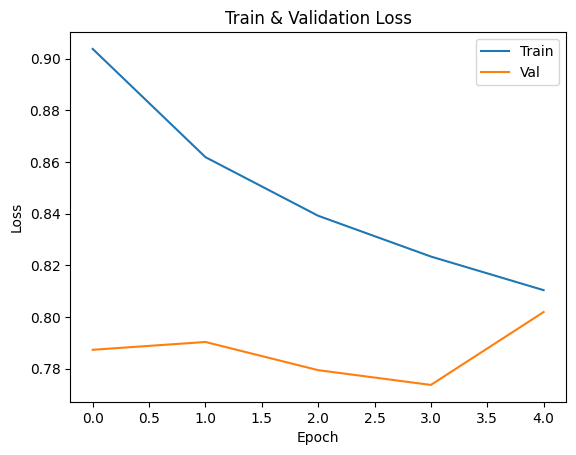

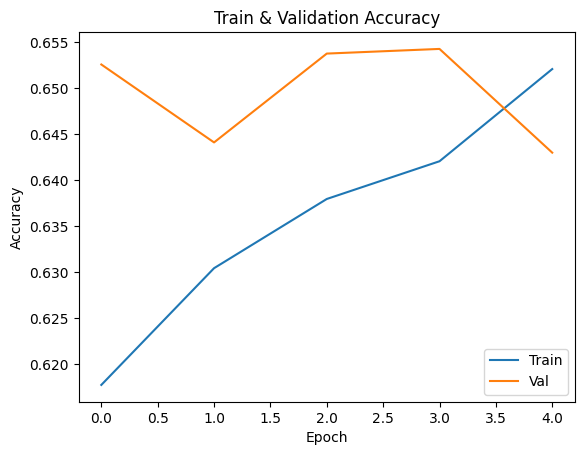

In [ ]:
# Trial 6 - change weight decay to 1e-3
# Results are similar to previous trials, with slightly better performance in the soft class
# Will test higher weight decay to understand our seperation from underfitting 
trial6Model = SecondModel()
trial6Model.name = "SecondModel_wd1e-3"
trainAcc, trainLoss, valAcc, valLoss, valF1 = train(trial6Model, trainLoaderWeighted, valLoader,
                                                    numEpochs = 20, learningRate = 0.003, batchSize = 128,
                                                    weightDecay = 1e-3)
plot_training_curve(trainAcc, trainLoss, valAcc, valLoss)

In [80]:
# Trial 6 Model Analysis
inspectModel6 = SecondModel()
inspectModel6.load_state_dict(torch.load("ModelSaves/SecondModel_wd1e-3_bestValF1"))
inspectModel6.eval()

allPreds, allLabels = [], []
with torch.no_grad():
    for tel, labels, staticFeats in valLoader:
        preds = torch.argmax(inspectModel6(tel, staticFeats), dim=1)
        allPreds.extend(preds.tolist())
        allLabels.extend(labels.tolist())

print("Trial 6 Classification Report + Confusion Matrix")
print(classification_report(allLabels, allPreds, target_names = ['Hard', 'Medium', 'Soft']))
print(confusion_matrix(allLabels, allPreds))

Trial 6 Classification Report + Confusion Matrix
              precision    recall  f1-score   support

        Hard       0.72      0.83      0.77     44867
      Medium       0.65      0.47      0.54     28352
        Soft       0.29      0.33      0.31      7814

    accuracy                           0.65     81033
   macro avg       0.55      0.54      0.54     81033
weighted avg       0.65      0.65      0.64     81033

[[37047  4192  3628]
 [12473 13233  2646]
 [ 2166  3050  2598]]


Epoch 1: Train Loss: 0.89791 Train Accuracy: 0.61843 Val. Loss: 0.77569 Val Acc: 0.65509 Val Macro F1: 0.54343
Epoch 2: Train Loss: 0.85362 Train Accuracy: 0.63209 Val. Loss: 0.78887 Val Acc: 0.65289 Val Macro F1: 0.52716
Epoch 3: Train Loss: 0.83200 Train Accuracy: 0.64110 Val. Loss: 0.78523 Val Acc: 0.65167 Val Macro F1: 0.52604
Epoch 4: Train Loss: 0.81559 Train Accuracy: 0.64375 Val. Loss: 0.78689 Val Acc: 0.65678 Val Macro F1: 0.51255
Epoch 5: Train Loss: 0.79254 Train Accuracy: 0.65647 Val. Loss: 0.80239 Val Acc: 0.64859 Val Macro F1: 0.51817
Epoch 6: Train Loss: 0.78492 Train Accuracy: 0.65540 Val. Loss: 0.80382 Val Acc: 0.65368 Val Macro F1: 0.51592
Epoch 7: Train Loss: 0.77576 Train Accuracy: 0.65932 Val. Loss: 0.80963 Val Acc: 0.64795 Val Macro F1: 0.51031
Epoch 8: Train Loss: 0.76551 Train Accuracy: 0.66330 Val. Loss: 0.80611 Val Acc: 0.65539 Val Macro F1: 0.51433
Epoch 9: Train Loss: 0.75862 Train Accuracy: 0.66653 Val. Loss: 0.81955 Val Acc: 0.64960 Val Macro F1: 0.51214
S

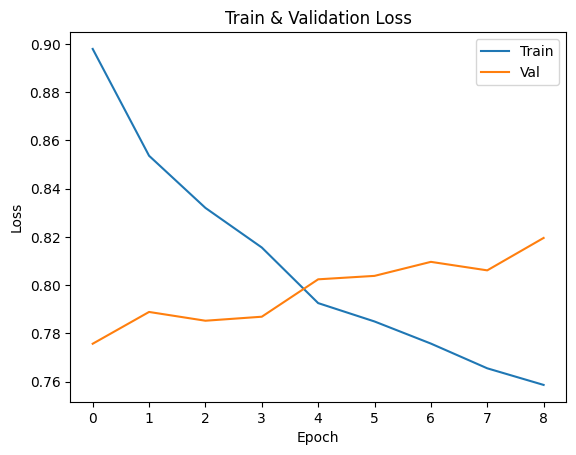

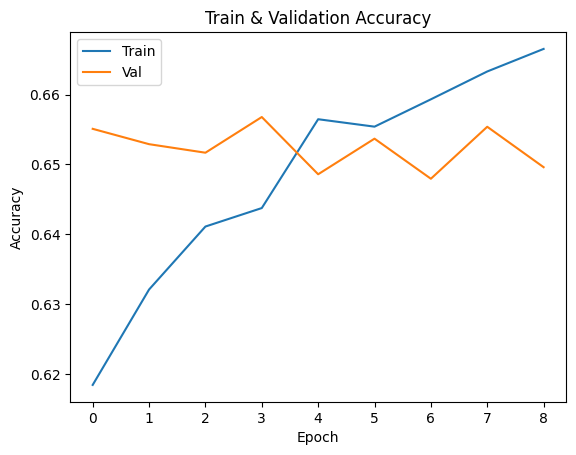

In [ ]:
# Trial 7 - weight decay 1e-5
# Trial 5 and 6 were neglibly different in accuracy, F1, and confusion matrix
# Experiment with lower weight decay to push model to overfit and potentially increase accuracy
trial7Model = SecondModel()
trial7Model.name = "SecondModel_wd1e-5"
trainAcc, trainLoss, valAcc, valLoss, valF1 = train(trial7Model, trainLoaderWeighted, valLoader,
                                                    numEpochs = 20, learningRate = 0.003, batchSize = 128,
                                                    weightDecay = 1e-5, earlyStopEpochs = 8)
plot_training_curve(trainAcc, trainLoss, valAcc, valLoss)

In [81]:
# Trial 7 Model Analysis
inspectModel7 = SecondModel()
inspectModel7.load_state_dict(torch.load("ModelSaves/SecondModel_wd1e-5_bestValF1"))
inspectModel7.eval()

allPreds, allLabels = [], []
with torch.no_grad():
    for tel, labels, staticFeats in valLoader:
        preds = torch.argmax(inspectModel7(tel, staticFeats), dim=1)
        allPreds.extend(preds.tolist())
        allLabels.extend(labels.tolist())

print("Trial 7 Classification Report + Confusion Matrix")
print(classification_report(allLabels, allPreds, target_names = ['Hard', 'Medium', 'Soft']))
print(confusion_matrix(allLabels, allPreds))

Trial 7 Classification Report + Confusion Matrix
              precision    recall  f1-score   support

        Hard       0.72      0.81      0.76     44867
      Medium       0.63      0.50      0.56     28352
        Soft       0.32      0.31      0.31      7814

    accuracy                           0.66     81033
   macro avg       0.55      0.54      0.54     81033
weighted avg       0.65      0.66      0.65     81033

[[36544  5172  3151]
 [12208 14152  1992]
 [ 2281  3145  2388]]


Epoch 1: Train Loss: 0.93547 Train Accuracy: 0.61398 Val. Loss: 0.77793 Val Acc: 0.65368 Val Macro F1: 0.52037
Epoch 2: Train Loss: 0.87739 Train Accuracy: 0.62267 Val. Loss: 0.80593 Val Acc: 0.63462 Val Macro F1: 0.50964
Epoch 3: Train Loss: 0.85607 Train Accuracy: 0.63438 Val. Loss: 0.80442 Val Acc: 0.64310 Val Macro F1: 0.51826
Epoch 4: Train Loss: 0.84155 Train Accuracy: 0.63820 Val. Loss: 0.79743 Val Acc: 0.64766 Val Macro F1: 0.52477
Epoch 5: Train Loss: 0.82702 Train Accuracy: 0.64040 Val. Loss: 0.80490 Val Acc: 0.64260 Val Macro F1: 0.51022
Epoch 6: Train Loss: 0.81984 Train Accuracy: 0.64916 Val. Loss: 0.81410 Val Acc: 0.63994 Val Macro F1: 0.51520
Epoch 7: Train Loss: 0.81348 Train Accuracy: 0.65035 Val. Loss: 0.81220 Val Acc: 0.64226 Val Macro F1: 0.51862
Epoch 8: Train Loss: 0.80648 Train Accuracy: 0.65172 Val. Loss: 0.81889 Val Acc: 0.64027 Val Macro F1: 0.50860
Epoch 9: Train Loss: 0.80152 Train Accuracy: 0.65469 Val. Loss: 0.82232 Val Acc: 0.64002 Val Macro F1: 0.51238
E

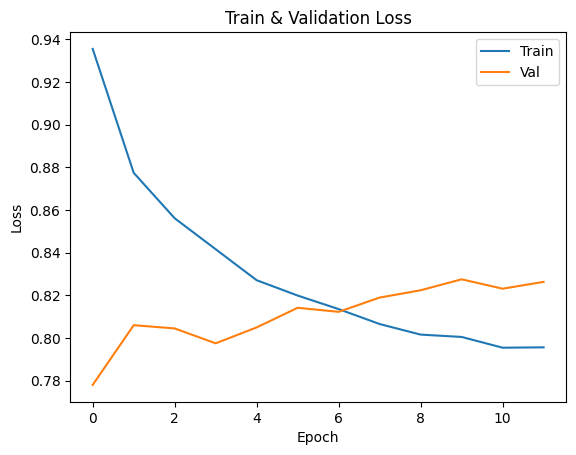

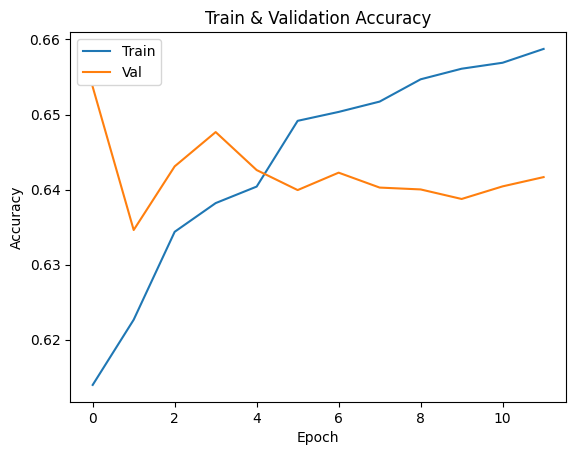

In [73]:
# Trial 8 — lower LR, more epochs, wd = 1e-4
# tests whether slower/more careful convergence beats the faster 0.003 runs
trial8Model = SecondModel()
trial8Model.name = "SecondModel_lowlr"
trainAcc, trainLoss, valAcc, valLoss, valF1 = train(trial8Model, trainLoaderWeighted, valLoader,
                                                    numEpochs = 30, learningRate = 0.0005, batchSize = 128,
                                                    weightDecay = 1e-4, earlyStopEpochs = 8)
plot_training_curve(trainAcc, trainLoss, valAcc, valLoss)

In [82]:
# Trial 8 Model Analysis
inspectModel8 = SecondModel()
inspectModel8.load_state_dict(torch.load("ModelSaves/SecondModel_lowlr_bestValF1"))
inspectModel8.eval()

allPreds, allLabels = [], []
with torch.no_grad():
    for tel, labels, staticFeats in valLoader:
        preds = torch.argmax(inspectModel8(tel, staticFeats), dim=1)
        allPreds.extend(preds.tolist())
        allLabels.extend(labels.tolist())

print("Trial 8 Classification Report + Confusion Matrix")
print(classification_report(allLabels, allPreds, target_names = ['Hard', 'Medium', 'Soft']))
print(confusion_matrix(allLabels, allPreds))

Trial 8 Classification Report + Confusion Matrix
              precision    recall  f1-score   support

        Hard       0.70      0.83      0.76     44867
      Medium       0.63      0.46      0.53     28352
        Soft       0.29      0.27      0.28      7814

    accuracy                           0.65     81033
   macro avg       0.54      0.52      0.52     81033
weighted avg       0.64      0.65      0.64     81033

[[37326  4697  2844]
 [12906 13030  2416]
 [ 2742  2946  2126]]


In [ ]:
# Oversampling may have been too aggressive for the samll num of Soft sampleWeights
# Less oversampling of minority classes
gentleWeights = rawWeightFormula ** 0.35

# Gentler class sampling
gentleSampleWeights = nnTrainDF['TireCompound'].map(compToIdx).map(
    {classIdx: weight for classIdx, weight in enumerate(gentleWeights)}
).values

# Samples selected based on gentler weights
gentleSampler = WeightedRandomSampler(gentleSampleWeights, num_samples = len(gentleSampleWeights), replacement = True)

# Load training set based on sampler
trainLoaderGentle = DataLoader(TelemetryDataset(nnTrainDF), batch_size = 128, sampler = gentleSampler)

Epoch 1: Train Loss: 0.88316 Train Accuracy: 0.61980 Val. Loss: 0.74922 Val Acc: 0.66068 Val Macro F1: 0.48757
Epoch 2: Train Loss: 0.84069 Train Accuracy: 0.62549 Val. Loss: 0.76862 Val Acc: 0.66076 Val Macro F1: 0.48504
Epoch 3: Train Loss: 0.81735 Train Accuracy: 0.63038 Val. Loss: 0.78655 Val Acc: 0.64930 Val Macro F1: 0.48416
Epoch 4: Train Loss: 0.80407 Train Accuracy: 0.63930 Val. Loss: 0.78141 Val Acc: 0.66101 Val Macro F1: 0.48837
Epoch 5: Train Loss: 0.78312 Train Accuracy: 0.64530 Val. Loss: 0.78679 Val Acc: 0.65528 Val Macro F1: 0.48781
Epoch 6: Train Loss: 0.77458 Train Accuracy: 0.65541 Val. Loss: 0.80331 Val Acc: 0.65304 Val Macro F1: 0.50053
Epoch 7: Train Loss: 0.76875 Train Accuracy: 0.65487 Val. Loss: 0.80253 Val Acc: 0.65381 Val Macro F1: 0.48854
Epoch 8: Train Loss: 0.75549 Train Accuracy: 0.66080 Val. Loss: 0.80739 Val Acc: 0.65628 Val Macro F1: 0.49956
Epoch 9: Train Loss: 0.75154 Train Accuracy: 0.66287 Val. Loss: 0.82084 Val Acc: 0.65229 Val Macro F1: 0.49262
E

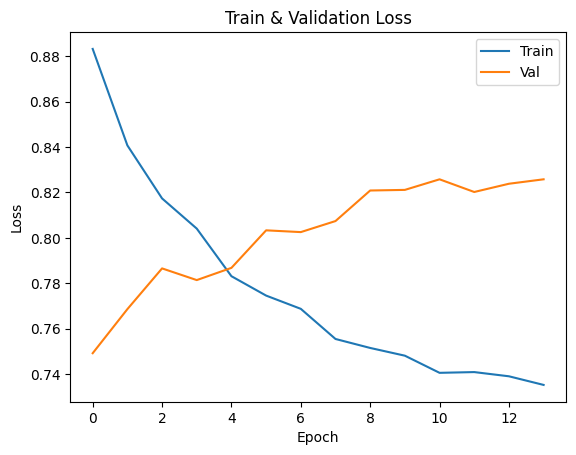

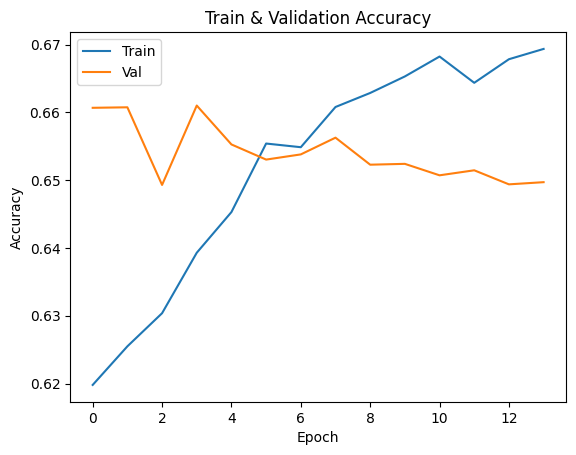

In [76]:
# Trial 9 — gentler oversampling + wd=1e-4
trial9Model = SecondModel()
trial9Model.name = "SecondModel_gentlesample"
trainAcc, trainLoss, valAcc, valLoss, valF1 = train(trial9Model, trainLoaderGentle, valLoader,
                                                    numEpochs = 20, learningRate = 0.003, batchSize = 128,
                                                    weightDecay = 1e-4, earlyStopEpochs = 8)
plot_training_curve(trainAcc, trainLoss, valAcc, valLoss)

In [83]:
# Trial 9 Model Analysis
inspectModel9 = SecondModel()
inspectModel9.load_state_dict(torch.load("ModelSaves/SecondModel_gentlesample_bestValF1"))
inspectModel9.eval()

allPreds, allLabels = [], []
with torch.no_grad():
    for tel, labels, staticFeats in valLoader:
        preds = torch.argmax(inspectModel9(tel, staticFeats), dim=1)
        allPreds.extend(preds.tolist())
        allLabels.extend(labels.tolist())

print("Trial 9 Classification Report + Confusion Matrix")
print(classification_report(allLabels, allPreds, target_names = ['Hard', 'Medium', 'Soft']))
print(confusion_matrix(allLabels, allPreds))

Trial 9 Classification Report + Confusion Matrix
              precision    recall  f1-score   support

        Hard       0.69      0.84      0.76     44867
      Medium       0.63      0.49      0.55     28352
        Soft       0.27      0.15      0.19      7814

    accuracy                           0.65     81033
   macro avg       0.53      0.49      0.50     81033
weighted avg       0.63      0.65      0.63     81033

[[37868  5162  1837]
 [13174 13903  1275]
 [ 3510  3157  1147]]


In [ ]:
# Oversampling has mostly hit a dead end
# Going to assess the capacity side once more
class ThirdModel(nn.Module):
    def __init__(self, numClasses = 3, cnnChannels = 32, lstmHidden = 64, numStaticFeats = 2, dropoutP = 0.3):
        super(ThirdModel, self).__init__()
        self.name = "ThirdModel"

        # Two conv blocks instead of one
        self.conv1 = nn.Conv1d(in_channels = 4, out_channels = cnnChannels, kernel_size = 5, padding = 2)
        self.bn1 = nn.BatchNorm1d(cnnChannels)
        self.conv2 = nn.Conv1d(in_channels = cnnChannels, out_channels = cnnChannels, kernel_size = 3, padding = 1)
        self.bn2 = nn.BatchNorm1d(cnnChannels)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool1d(kernel_size = 2)

        # Wider, BiLSTM
        self.lstm = nn.LSTM(input_size = cnnChannels, hidden_size = lstmHidden, batch_first = True, bidirectional = True)
        lstmOutDim = lstmHidden * 2

        # Static branch gets more capacity
        self.staticBranch = nn.Sequential(
            nn.Linear(numStaticFeats, 32), nn.ReLU(),
            nn.Linear(32, 32), nn.ReLU(),
        )

        self.dropout = nn.Dropout(dropoutP)
        self.head = nn.Sequential(
            nn.Linear(lstmOutDim + 32, 64), nn.ReLU(),
            nn.Dropout(dropoutP),
            nn.Linear(64, numClasses),
        )

    def forward(self, x, staticFeats):
        x = self.pool(self.relu(self.bn1(self.conv1(x))))
        x = self.relu(self.bn2(self.conv2(x)))
        x = x.permute(0, 2, 1)
        _, (hidden, _) = self.lstm(x)
        hiddenCat = torch.cat([hidden[-2], hidden[-1]], dim  =1)  # bidirectional final states
        staticEmbed = self.staticBranch(staticFeats)
        combined = torch.cat([hiddenCat, staticEmbed], dim = 1)
        return self.head(self.dropout(combined))

Epoch 1: Train Loss: 0.88812 Train Accuracy: 0.61455 Val. Loss: 0.77694 Val Acc: 0.64640 Val Macro F1: 0.54539
Epoch 2: Train Loss: 0.84224 Train Accuracy: 0.63307 Val. Loss: 0.76691 Val Acc: 0.65736 Val Macro F1: 0.53085
Epoch 3: Train Loss: 0.81740 Train Accuracy: 0.64837 Val. Loss: 0.79158 Val Acc: 0.64108 Val Macro F1: 0.51168
Epoch 4: Train Loss: 0.79926 Train Accuracy: 0.65327 Val. Loss: 0.80880 Val Acc: 0.63519 Val Macro F1: 0.51170
Epoch 5: Train Loss: 0.78466 Train Accuracy: 0.66611 Val. Loss: 0.82355 Val Acc: 0.63816 Val Macro F1: 0.52167
Epoch 6: Train Loss: 0.76091 Train Accuracy: 0.67598 Val. Loss: 0.84876 Val Acc: 0.63599 Val Macro F1: 0.52136
Stopping at 6 due to no improvements for 5 epochs


Best epoch: 1 (Val F1: 0.54539)


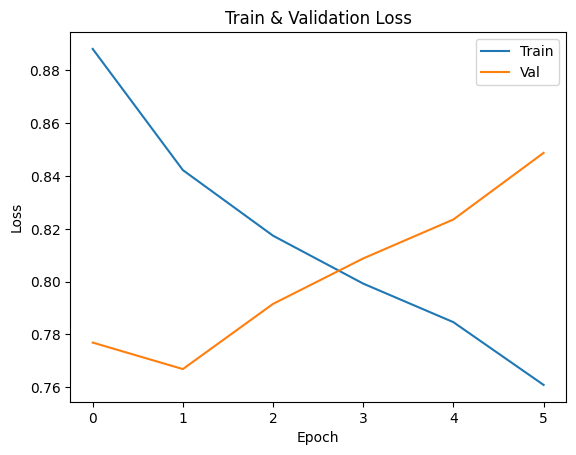

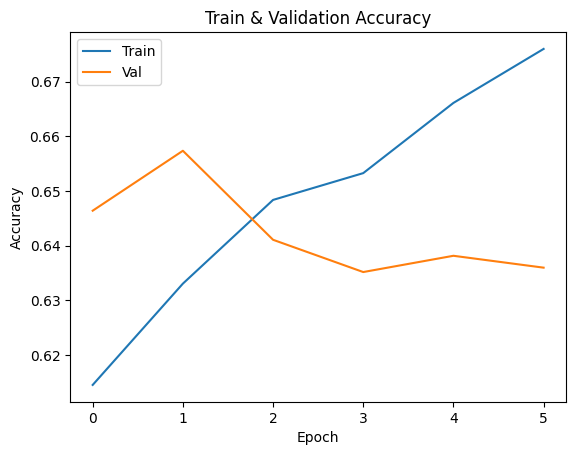

In [ ]:
# Trial 10 
trial10Model = ThirdModel()
trial10Model.name = "ThirdModel_v1"
trainAcc, trainLoss, valAcc, valLoss, valF1 = train(trial10Model, trainLoaderWeighted, valLoader,
                                                    numEpochs = 15, learningRate = 0.003, batchSize = 128,
                                                    weightDecay = 1e-4, earlyStopEpochs = 5)
plot_training_curve(trainAcc, trainLoss, valAcc, valLoss)

In [87]:
# Trial 10 Model Analysis
inspectModel10 = ThirdModel()
inspectModel10.load_state_dict(torch.load("ModelSaves/ThirdModel_v1_bestValF1"))
inspectModel10.eval()

allPreds, allLabels = [], []
with torch.no_grad():
    for tel, labels, staticFeats in valLoader:
        preds = torch.argmax(inspectModel10(tel, staticFeats), dim=1)
        allPreds.extend(preds.tolist())
        allLabels.extend(labels.tolist())

print("Trial 10 Classification Report + Confusion Matrix")
print(classification_report(allLabels, allPreds, target_names = ['Hard', 'Medium', 'Soft']))
print(confusion_matrix(allLabels, allPreds))

Trial 10 Classification Report + Confusion Matrix
              precision    recall  f1-score   support

        Hard       0.72      0.79      0.76     44867
      Medium       0.62      0.49      0.55     28352
        Soft       0.30      0.37      0.33      7814

    accuracy                           0.65     81033
   macro avg       0.55      0.55      0.55     81033
weighted avg       0.65      0.65      0.64     81033

[[35610  5400  3857]
 [11641 13910  2801]
 [ 1935  3019  2860]]


**Final Model Justification**: Trial 5 was selected. Overall equivalent performance to trial 10 but much smaller, the capacity increase to the 3rd model had no improvements. The model has demonstrated it's limits; nothing done resulted in signficant growth except for the dataset class balancing and the larger model. Lower level hyperparam tuning and further increased size should result in minimal improvement.

In [108]:
# Load the final model, use test set to get accuracy and F1 score
finalModel = inspectModel5
finalModel.eval()

testAcc, testF1 = getAccuracy(finalModel, testLoader)
print(f"Final Model Test accuracy: {testAcc:.3f}, Test Macro F1: {testF1:.3f}")

Final Model Test accuracy: 0.656, Test Macro F1: 0.554


In [126]:
# Final Model, Test Set
finalModel = inspectModel5
finalModel.eval()

allPreds, allLabels = [], []
with torch.no_grad():
    for tel, labels, staticFeats in valLoader:
        preds = torch.argmax(inspectModel5(tel, staticFeats), dim=1)
        allPreds.extend(preds.tolist())
        allLabels.extend(labels.tolist())

print("Final Classification Report + Confusion Matrix (Trial 5, Test Set)")
print(classification_report(allLabels, allPreds, target_names = ['Hard', 'Medium', 'Soft']))
print(confusion_matrix(allLabels, allPreds))

Final Classification Report + Confusion Matrix (Trial 5, Test Set)
              precision    recall  f1-score   support

        Hard       0.72      0.82      0.76     44867
      Medium       0.64      0.46      0.53     28352
        Soft       0.30      0.36      0.32      7814

    accuracy                           0.65     81033
   macro avg       0.55      0.55      0.54     81033
weighted avg       0.65      0.65      0.64     81033

[[36742  4396  3729]
 [12481 13031  2840]
 [ 2013  3013  2788]]


### Testing Final Model on New Data

In [109]:
# Test the model on untouched new data from the 2025 season
finalTestDf = pd.read_pickle('output/2025_samples.pkl')
newTestLoader = DataLoader(TelemetryDataset(finalTestDf), batch_size = 128, shuffle = False)

allPreds, allLabels = [], []
with torch.no_grad():
    for tel, labels, staticFeats in newTestLoader:
        preds = torch.argmax(finalModel(tel, staticFeats), dim=1)
        allPreds.extend(preds.tolist())
        allLabels.extend(labels.tolist())

print("Final Model Class. Report + Confusion Matrix on 2025 Season Data")
print(classification_report(allLabels, allPreds, target_names = ['Hard', 'Medium', 'Soft']))
print(confusion_matrix(allLabels, allPreds))
print("Class Ordering ['Hard', 'Medium', 'Soft']")

Final Model Class. Report + Confusion Matrix on 2025 Season Data
              precision    recall  f1-score   support

        Hard       0.59      0.77      0.67    135847
      Medium       0.62      0.42      0.50    124848
        Soft       0.23      0.22      0.22     35595

    accuracy                           0.56    296290
   macro avg       0.48      0.47      0.47    296290
weighted avg       0.56      0.56      0.55    296290

[[104521  20516  10810]
 [ 56570  52930  15348]
 [ 15873  11929   7793]]
Class Ordering ['Hard', 'Medium', 'Soft']


## Appendix (Report Stats)

In [125]:
# Qualatative Metric
# Pick a sample
testDataset = TelemetryDataset(nnTestDF)
case1Done, case2Done = False, False
for sampleIdx in range(len(testDataset)):
    
    sample, label, staticFeats = testDataset[sampleIdx]

    # Model expects a batch dimension
    inputBatch = sample.unsqueeze(0)
    staticFeatBatch = staticFeats.unsqueeze(0)

    finalModel.eval() # eval mode
    with torch.no_grad():
        prediction = finalModel(inputBatch, staticFeatBatch)
        probs = torch.softmax(prediction, dim = 1).squeeze(0)
        predLabel = torch.argmax(probs).item()

    if ((idxToComp[label] == 'Medium') and (idxToComp[predLabel] == "Hard") and case1Done is False):
        print(f"\nSample {sampleIdx} Qualitative Analysis")
        print(f"Ground Truth: {idxToComp[label]}   Model Prediction: {idxToComp[predLabel]}")
        print(f"Class probabilities: Hard: {probs[0]:.2f}, Medium: {probs[1]:.2f}, Soft: {probs[2]:.2f}")
        case1Done = True

    if ((idxToComp[label] == 'Soft') and (idxToComp[predLabel] == "Medium") and case2Done is False):
        print(f"\nSample {sampleIdx} Qualitative Analysis")
        print(f"Ground Truth: {idxToComp[label]}   Model Prediction: {idxToComp[predLabel]}")
        print(f"Class probabilities: Hard: {probs[0]:.2f}, Medium: {probs[1]:.2f}, Soft: {probs[2]:.2f}")
        case2Done = True

    if (case1Done is True and case2Done is True):
        break


Sample 750 Qualitative Analysis
Ground Truth: Soft   Model Prediction: Medium
Class probabilities: Hard: 0.13, Medium: 0.59, Soft: 0.28

Sample 1019 Qualitative Analysis
Ground Truth: Medium   Model Prediction: Hard
Class probabilities: Hard: 0.58, Medium: 0.28, Soft: 0.14


In [54]:
# For report
print("# of trainable parameters:", sum(p.numel() for p in primaryModel.parameters() if p.requires_grad))

# of trainable parameters: 6835


In [78]:
# For report
sndaryModel = SecondModel()
print("# of trainable parameters in SecondModel:", sum(p.numel() for p in sndaryModel.parameters() if p.requires_grad))

# of trainable parameters in SecondModel: 60707


In [110]:
# For report
thirdiary = ThirdModel()
print("# of trainable parameters in SecondModel:", sum(p.numel() for p in thirdiary.parameters() if p.requires_grad))

# of trainable parameters in SecondModel: 65731
